In [1]:
import itertools
import warnings
from pathlib import Path

import anndata as ad
import colorcet as cc
import harmonypy
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import squidpy as sq
from matplotlib.colors import to_hex, to_rgb
from scipy.io import mmread
from sklearn.cross_decomposition import CCA, PLSSVD, PLSCanonical
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from spatialleiden import multiplex_leiden

warnings.filterwarnings("ignore", category=FutureWarning)

/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


# COSIE mouse brain (6-OHDA), all FMP-10 slides — MuData and SpatialLeiden

Same pipeline as `01_build_mudata.ipynb`, but for every FMP-10 mouse slide of Vicari et al., *Nat Biotechnol* 2024 (Mendeley Data `w7nw4km7xd`). `DATASET` in the configuration selects the data: `"all"` loads and clusters all 8 sections of both slides together, `"striatum"` or `"substantia_nigra"` one slide. With `"all"`, a cluster can be shared by both tissues, but most clusters are expected to be tissue-specific; Harmony is run within each slide only (striatum and substantia nigra differ biologically and must not be aligned).

| `DATASET` | slide | tissue | sections with MALDI | MALDI-free control | lesion region |
|---|---|---|---|---|---|
| `striatum` | `V11L12-109` | striatum | A1 (mPD1), B1 (mPD3), C1 (mPD4) | D1 (mPD3) | CP |
| `substantia_nigra` | `V11T16-085` | substantia nigra / midbrain | A1 (mPD1), B1 (mPD3), C1 (mPD4) | D1 (mPD4) | VTA-SNc |

Sections, mice, Space Ranger paths and MALDI status are read from `metadata.csv` of the original study. The controls are the sections without MALDI (`Laser = nL`, one per slide). The lesion annotation covers the whole hemisphere, but 6-OHDA acts on the dopaminergic system, so the lesion is also scored within the lesion region of each slide (`mdata.obs["in_lesion_region"]`) (striatum: CP, dopaminergic terminals; substantia nigra: VTA-SNc, dopaminergic cell bodies). Region names are harmonised between sections (`VTA-SNpc` → `VTA-SNc`); `ulcer` (tissue damage) is treated as unannotated. Results go to `results/Cosie_Clustering/<DATASET>/`.

**Modalities.**
- `rna` — Visium counts from Space Ranger, all sections.
- `msi` — MALDI-MSI registered to the Visium spots by the original authors (`misc/se.multi.list`, exported with `00_export_msi_spots.R`). Both slides share the same 1,538 FMP-10 m/z features.

**SpatialLeiden inputs.** Each modality gets a kNN graph on its own spots (`mod[m].obsp["connectivities"]`). Because a modality can be missing in a section, the same graphs are also stored padded to all spots in `mdata.obsp["<mod>_connectivities"]`, where unmeasured spots have no edges; the spatial graph is `mdata.obsp["spatial_connectivities"]`. These padded graphs go directly into `spatialleiden.multiplex_leiden`.


# Configuration

In [2]:
data_dir = Path("../data/01_mouse_brain_MALDI_visium")
msi_dir = data_dir / "processed" / "msi_spots"
# FMP-10 mouse slides: A1-C1 with MALDI, D1 = MALDI-free control on the same slide
DATASET = "striatum"  # "all" (both slides, 8 sections), "striatum" or "substantia_nigra"
# MSI preprocessing: "log" = TIC + log1p over all MSI sections; "maldipy" = TIC, regress out TIC, scale each m/z,
# per slide (as MALDIpy maldi_norm). Results go to a subfolder per variant (results/.../msi_<variant>/).
msi_preprocessing = "log"
# lesion_region: annotated region where the 6-OHDA lesion acts (lesion is also scored there only)
SLIDES = {
    "V11L12-109": {"tissue": "striatum", "lesion_region": "CP"},
    "V11T16-085": {"tissue": "substantia_nigra", "lesion_region": "VTA-SNc"},
}
slides = list(SLIDES) if DATASET == "all" else [s for s, v in SLIDES.items() if v["tissue"] == DATASET]
LESION_REGION = {s: SLIDES[s]["lesion_region"] for s in slides}
lesion_label = "/".join(LESION_REGION.values())
# clusters for the fixed-k comparison; not listed = annotated regions + one per lesion region (its lesioned side)
N_CLUSTERS_TARGET = {"striatum": 21}
# harmonise region names between sections; None = not a region (tissue damage), treated as unannotated
REGION_RENAME = {"VTA-SNpc": "VTA-SNc", "ulcer": None}

out_dir = Path("../results/Cosie_Clustering") / DATASET / f"msi_{msi_preprocessing}"
out_dir.mkdir(parents=True, exist_ok=True)
out_file = out_dir / f"mouse_brain_6OHDA_{DATASET}.h5mu"

# sections, mice and Space Ranger outs from the metadata table of the original study (one RNA library per section)
study_meta = pd.read_csv(data_dir / "metadata.csv")
study_meta = study_meta[study_meta["ArrayID"].isin(slides) & (study_meta["Data.Type"] == "RNA")].set_index("Sample.ID").sort_index()
SECTIONS = {s: (row["sample"], data_dir / row["Path.To.File"].lstrip("/")) for s, row in study_meta.iterrows()}
control_sections = study_meta.index[study_meta["Laser"] == "nL"].tolist()  # sections without MALDI, one per slide
display(study_meta[["sample", "Brain.area", "Laser"]].rename(columns={"sample": "mouse"}))
print("controls (no MALDI):", control_sections)
ANNOTATIONS = ["RegionLoupe", "region", "lesion"]  # per-spot csv files in each outs folder

n_hvg = 3000
n_pcs = {"rna": 50, "msi": 30}
n_neighbors = 15
# RNA embedding for every RNA-based graph (kNN graph, smoothed RNA, RNA bridge):
# "X_pca_harmony" = PCs corrected for section with Harmony, "X_pca" = uncorrected PCs
rna_rep = "X_pca_harmony"
# MSI embedding for the MSI kNN graph: "X_pca" (uncorrected) or "X_pca_harmony" (corrected for section within each slide);
# see "MSI batch effect" below (the masking experiment refits its own MSI PCA without the masked section)
msi_rep = "X_pca"
seed = 42

,mouse,Brain.area,Laser
Sample.ID,,,
V11L12-109_A1,mPD1,Striatum,yL
V11L12-109_B1,mPD3,Striatum,yL
V11L12-109_C1,mPD4,Striatum,yL
V11L12-109_D1,mPD3,Striatum,nL


controls (no MALDI): ['V11L12-109_D1']


# Load data

## RNA

In [3]:
def load_rna(section, mouse, outs):
    adata = sq.read.visium(outs, counts_file="filtered_feature_bc_matrix.h5", library_id=section)
    adata.var_names_make_unique()
    adata = adata[adata.obs["in_tissue"] == 1].copy()

    for name in ANNOTATIONS:
        ann = pd.read_csv(outs / f"{name}.csv", index_col=0).iloc[:, 0]
        if name == "RegionLoupe":
            ann = ann.map(lambda r: REGION_RENAME.get(r, r))
        adata.obs[name] = ann.reindex(adata.obs_names).astype("category")

    adata.obs["barcode"] = adata.obs_names
    adata.obs["section"] = section
    adata.obs["mouse"] = mouse
    adata.obs_names = section + "_" + adata.obs_names
    return adata


rna_sections = {section: load_rna(section, *info) for section, info in SECTIONS.items()}
for section, a in rna_sections.items():
    print(f"{section}: {a.n_obs:,} spots, {a.n_vars:,} genes; RegionLoupe missing for {a.obs['RegionLoupe'].isna().sum()} spots")

/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


V11L12-109_A1: 2,675 spots, 32,285 genes; RegionLoupe missing for 291 spots
V11L12-109_B1: 3,120 spots, 32,285 genes; RegionLoupe missing for 300 spots
V11L12-109_C1: 2,918 spots, 32,285 genes; RegionLoupe missing for 252 spots
V11L12-109_D1: 3,017 spots, 32,285 genes; RegionLoupe missing for 252 spots


## MALDI-MSI

Only sections with MALDI data have an export in `processed/msi_spots` (`D1` has none).

In [4]:
def load_msi(section):
    folder = msi_dir / section
    counts = sp.csr_matrix(mmread(folder / "matrix.mtx").T)  # exported as features x spots
    barcodes = (folder / "barcodes.tsv").read_text().split()
    features = (folder / "features.tsv").read_text().split()
    adata = ad.AnnData(counts, obs=pd.DataFrame(index=[f"{section}_{bc}" for bc in barcodes]), var=pd.DataFrame(index=features))
    adata.obs["section"] = section
    return adata


msi_sections = {s: load_msi(s) for s in SECTIONS if (msi_dir / s).exists()}
for section, a in msi_sections.items():
    n_in_rna = a.obs_names.isin(rna_sections[section].obs_names).sum()
    print(f"{section}: {a.n_obs:,} spots ({n_in_rna:,} also in RNA), {a.n_vars:,} m/z features")

# the FMP-10 sections share one m/z feature list
features = [a.var_names for a in msi_sections.values()]
assert all(f.equals(features[0]) for f in features), "m/z features differ between sections"

/tmp/ipykernel_3864453/938607360.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  counts = sp.csr_matrix(mmread(folder / "matrix.mtx").T)  # exported as features x spots
/tmp/ipykernel_3864453/938607360.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix

V11L12-109_A1: 2,206 spots (2,206 also in RNA), 1,538 m/z features
V11L12-109_B1: 2,526 spots (2,526 also in RNA), 1,538 m/z features
V11L12-109_C1: 2,379 spots (2,379 also in RNA), 1,538 m/z features


# Preprocessing and per-modality kNN graphs

Each modality is processed jointly over all sections that contain it, so its kNN graph links spots across sections.

In [5]:
rna = ad.concat(rna_sections, merge="same", uns_merge="unique")
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=n_hvg, batch_key="section")
sc.pp.pca(rna, n_comps=n_pcs["rna"], mask_var="highly_variable", random_state=seed)
# Harmony on the RNA PCs, batch = section, run within each slide: sections of one tissue are aligned,
# striatum and substantia nigra are not (they differ biologically). Used only if rna_rep == "X_pca_harmony".
rna.obs["slide"] = rna.obs["section"].astype(str).str.split("_").str[0]
rna.obsm["X_pca_harmony"] = rna.obsm["X_pca"].copy()
for slide_name in rna.obs["slide"].unique():
    rows = (rna.obs["slide"] == slide_name).to_numpy()
    ho = harmonypy.run_harmony(rna.obsm["X_pca"][rows], rna.obs.loc[rows, ["section"]], "section", random_state=seed, verbose=False)
    Z = np.asarray(ho.Z_corr)
    rna.obsm["X_pca_harmony"][rows] = Z if Z.shape[0] == rows.sum() else Z.T
sc.pp.neighbors(rna, n_neighbors=n_neighbors, use_rep=rna_rep, random_state=seed)
print("RNA kNN graph on", rna_rep)

# MSI, msi_preprocessing = "maldipy": as in MALDIpy (single_cell.maldi_norm): TIC normalisation, regress out TIC,
# scale each m/z; no log. Done per slide, because the slides differ strongly in sparsity (striatum ~75% zeros,
# substantia nigra ~22%). msi_preprocessing = "log": TIC normalisation + log1p over all MSI sections (previous version).
# All m/z are used: no detection filter, because the lesion markers (dopamine m/z 674.28833 and others) are
# detected only in the intact CP (~15-40% of spots), so their zeros are signal.
msi = ad.concat(msi_sections, merge="same")
msi.obs["slide"] = msi.obs["section"].astype(str).str.split("_").str[0]
msi.layers["counts"] = msi.X.copy()
lognorm = msi.copy()  # log TIC-normalised intensities of all m/z, only for plots
sc.pp.normalize_total(lognorm)
sc.pp.log1p(lognorm)
msi.layers["lognorm"] = lognorm.X
del lognorm
msi_slides = msi.obs["slide"].unique()
if msi_preprocessing == "maldipy":
    X = np.zeros(msi.shape, dtype=np.float32)
    for slide_name in msi_slides:
        rows = (msi.obs["slide"] == slide_name).to_numpy()
        a = ad.AnnData(msi.layers["counts"][rows].copy())
        a.obs["total_counts"] = np.asarray(a.X.sum(axis=1)).ravel()
        sc.pp.normalize_total(a)
        sc.pp.regress_out(a, ["total_counts"])
        sc.pp.scale(a, max_value=10)
        X[rows] = a.X
    msi.X = X
elif msi_preprocessing == "log":
    msi.X = msi.layers["lognorm"].copy()
else:
    raise ValueError(f"unknown msi_preprocessing: {msi_preprocessing}")
print("MSI preprocessing:", msi_preprocessing)
sc.pp.pca(msi, n_comps=n_pcs["msi"], random_state=seed)
# Harmony on the MSI PCs, as for RNA (batch = section, within each slide). Used only if msi_rep == "X_pca_harmony".
msi.obsm["X_pca_harmony"] = msi.obsm["X_pca"].copy()
for slide_name in msi_slides:
    rows = (msi.obs["slide"] == slide_name).to_numpy()
    ho = harmonypy.run_harmony(msi.obsm["X_pca"][rows], msi.obs.loc[rows, ["section"]], "section", random_state=seed, verbose=False)
    Z = np.asarray(ho.Z_corr)
    msi.obsm["X_pca_harmony"][rows] = Z if Z.shape[0] == rows.sum() else Z.T
sc.pp.neighbors(msi, n_neighbors=n_neighbors, use_rep=msi_rep, random_state=seed)
print("MSI kNN graph on", msi_rep)
for name, a in {"rna": rna, "msi": msi}.items():
    print(f"{name}: {a.n_obs:,} spots x {a.n_vars:,} features")

RNA kNN graph on X_pca_harmony
MSI preprocessing: log
MSI kNN graph on X_pca
rna: 11,730 spots x 32,285 features
msi: 7,111 spots x 1,538 features


# Assemble MuData

In [6]:
mdata = md.MuData({"rna": rna, "msi": msi})

# spot-level metadata from the RNA object (RNA covers every spot)
obs_cols = ["section", "mouse", "barcode", "array_row", "array_col", *ANNOTATIONS]
mdata.obs = mdata.obs.join(rna.obs[obs_cols].rename(columns=lambda c: c), how="left")
mdata.obs["has_msi"] = mdata.obs_names.isin(msi.obs_names)
mdata.obs["slide"] = mdata.obs["section"].astype(str).str.split("_").str[0]
# spots in the lesion region of their slide (CP in the striatum, VTA-SNc in the substantia nigra)
mdata.obs["in_lesion_region"] = (mdata.obs["RegionLoupe"].astype(str) == mdata.obs["slide"].map(LESION_REGION)).to_numpy()
mdata.obsm["spatial"] = rna[mdata.obs_names].obsm["spatial"]
mdata.uns["spatial"] = rna.uns["spatial"]

assert mdata.obs_names.equals(rna.obs_names), "every spot should have RNA"
print(mdata)

MuData object with n_obs × n_vars = 11730 × 33823
  obs:	'section', 'mouse', 'barcode', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'has_msi', 'slide', 'in_lesion_region'
  uns:	'spatial'
  obsm:	'spatial'
  2 modalities
    rna:	11730 × 32285
      obs:	'in_tissue', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'barcode', 'section', 'mouse', 'slide'
      var:	'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
      uns:	'spatial', 'log1p', 'hvg', 'pca', 'neighbors'
      obsm:	'spatial', 'X_pca', 'X_pca_harmony'
      varm:	'PCs'
      layers:	None, 'counts'
      obsp:	'distances', 'connectivities'
    msi:	7111 × 1538
      obs:	'section', 'slide'
      uns:	'pca', 'neighbors'
      obsm:	'X_pca', 'X_pca_harmony'
      varm:	'PCs'
      layers:	None, 'counts', 'lognorm'
      obsp:	'distances', 'connectivities'


## Spatial graph

Visium hexagonal grid: the six direct neighbours of each spot, built per section so no edges cross sections.

In [7]:
spatial = ad.AnnData(obs=mdata.obs[["section"]].copy(), obsm={"spatial": mdata.obsm["spatial"]})
sq.gr.spatial_neighbors(spatial, coord_type="grid", n_neighs=6, n_rings=1, library_key="section")
mdata.obsp["spatial_connectivities"] = spatial.obsp["spatial_connectivities"]

degree = np.asarray(mdata.obsp["spatial_connectivities"].sum(axis=1)).ravel()
print("spatial neighbours per spot:", pd.Series(degree).value_counts().sort_index().to_dict())

INFO     Creating graph using `None` transform and `4` libraries.                                                  
spatial neighbours per spot: {1.0: 1, 2.0: 8, 3.0: 317, 4.0: 314, 5.0: 364, 6.0: 10726}


## Padded graphs for mosaic clustering

`<mod>_connectivities` has one row and column per spot of `mdata`; spots without that modality have no edges.

In [8]:
def pad_graph(graph, mod_obs_names, all_obs_names):
    idx = pd.Index(all_obs_names).get_indexer(mod_obs_names)
    assert (idx >= 0).all()
    g = graph.tocoo()
    return sp.csr_matrix((g.data, (idx[g.row], idx[g.col])), shape=(len(all_obs_names),) * 2)


for name in mdata.mod_names:
    mod = mdata.mod[name]
    mdata.obsp[f"{name}_connectivities"] = pad_graph(mod.obsp["connectivities"], mod.obs_names, mdata.obs_names)

summary = pd.DataFrame({
    name: mdata.obs.assign(has_edges=np.asarray(mdata.obsp[f"{name}_connectivities"].sum(axis=1)).ravel() > 0)
    .groupby("section")["has_edges"].mean()
    for name in [*mdata.mod_names, "spatial"]
})
summary  # fraction of spots with edges in each graph

,rna,msi,spatial
section,,,
V11L12-109_A1,1.0,0.824673,1.0
V11L12-109_B1,1.0,0.809615,1.0
V11L12-109_C1,1.0,0.815284,1.0
V11L12-109_D1,1.0,0.000000,1.0


# Sanity checks

Region annotation, lesion side and a few modality summaries per section. MSI on the Visium grid should show the tissue shape and anatomical structure if the registration is correct.

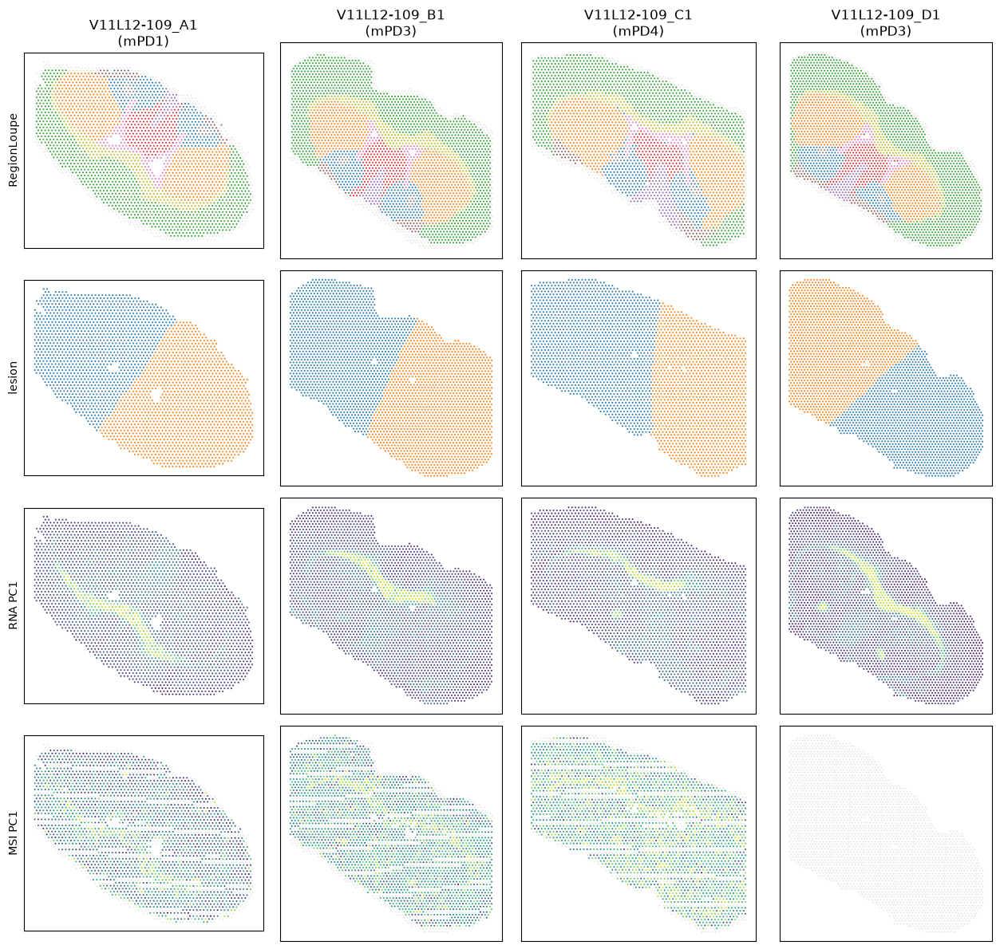

In [9]:
plot_cols = {
    "RegionLoupe": mdata.obs["RegionLoupe"],
    "lesion": mdata.obs["lesion"],
    "RNA PC1": pd.Series(rna.obsm["X_pca"][:, 0], index=rna.obs_names),
    "MSI PC1": pd.Series(msi.obsm["X_pca"][:, 0], index=msi.obs_names),
}
sections = list(SECTIONS)
fig, axes = plt.subplots(len(plot_cols), len(sections), figsize=(3.2 * len(sections), 3 * len(plot_cols)), squeeze=False)
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])

for row, (label, values) in enumerate(plot_cols.items()):
    for col, section in enumerate(sections):
        ax = axes[row, col]
        spots = mdata.obs_names[mdata.obs["section"] == section]
        vals = values.reindex(spots)
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=2, c="#e5e5e5", linewidth=0)
        shown = vals.dropna().index
        if isinstance(vals.dtype, pd.CategoricalDtype):
            codes = vals[shown].cat.codes
            ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=2, c=codes, cmap=cc.cm.glasbey_category10, vmin=0, vmax=255, linewidth=0)
        else:
            ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=2, c=vals[shown], cmap="viridis", linewidth=0)
        ax.set(aspect=1, xticks=[], yticks=[])
        ax.invert_yaxis()
        if row == 0:
            ax.set_title(f"{section}\n({mdata.obs.loc[spots, 'mouse'].iloc[0]})")
        if col == 0:
            ax.set_ylabel(label)
fig.tight_layout()
plt.show()

## Section metadata and RNA batch effect (Harmony)

`metadata.csv` from the original study lists mouse and MALDI status per section (`Laser = nL`: no MALDI, D1 is the MALDI-free control on the same slide). The RNA UMAP coloured by section shows whether sections separate (batch effect, e.g. D1 without MALDI processing). Harmony (`harmonypy`, computed in the preprocessing cell) corrects the RNA PCs for `section` within each slide and stores them in `rna.obsm["X_pca_harmony"]`. `rna_rep` in the configuration decides which embedding all RNA-based graphs use (kNN graph, smoothed RNA, RNA bridge). *Same-section neighbours* is the fraction of each spot's 15 RNA neighbours in its own section, compared with the fraction expected if sections were fully mixed.

,mouse,Condition,Matrix,MALDI laser,Protocol,Brain.area,n_spots
Sample.ID,,,,,,,
V11L12-109_A1,mPD1,mPD,FMP-10,yL,Sma,Striatum,2675
V11L12-109_B1,mPD3,mPD,FMP-10,yL,Sma,Striatum,3120
V11L12-109_C1,mPD4,mPD,FMP-10,yL,Sma,Striatum,2918
V11L12-109_D1,mPD3,mPD,FMP-10,nL,Visium_iCtrl,Striatum,3017


,before Harmony,after Harmony,expected if mixed within slide
same-section neighbours,,,
V11L12-109_A1,0.315,0.228,0.228
V11L12-109_B1,0.333,0.231,0.266
V11L12-109_C1,0.437,0.290,0.249
V11L12-109_D1,0.645,0.540,0.257


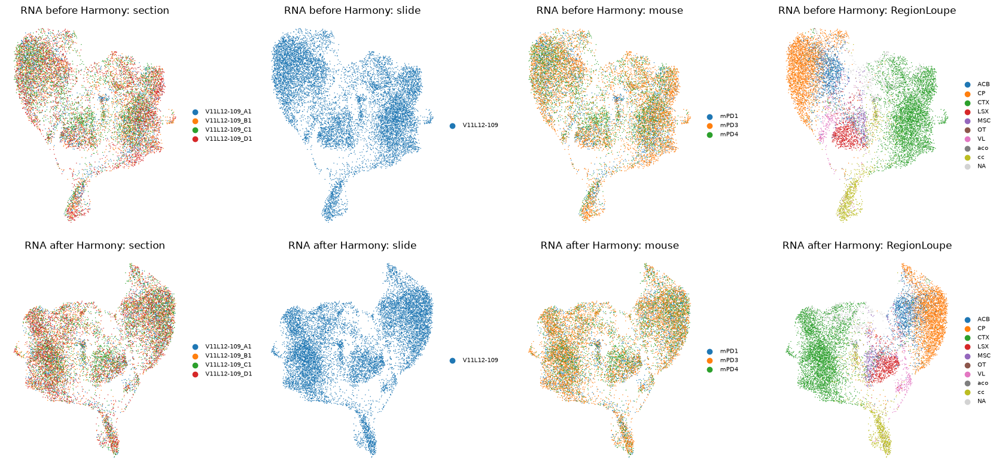

In [10]:
# section metadata of the original study (one row per Visium RNA library)
meta = pd.read_csv(data_dir / "metadata.csv")
meta = (meta[(meta["ArrayID"].isin(slides)) & (meta["Data.Type"] == "RNA")]
        .set_index("Sample.ID")[["sample", "Condition", "Matrix", "Laser", "Protocol", "Brain.area"]]
        .rename(columns={"sample": "mouse", "Laser": "MALDI laser"}))
meta["n_spots"] = rna.obs["section"].value_counts().reindex(meta.index)
display(meta)


def same_section_fraction(rep):
    tmp = ad.AnnData(obs=rna.obs[["section"]].copy(), obsm={rep: rna.obsm[rep]})
    sc.pp.neighbors(tmp, n_neighbors=n_neighbors, use_rep=rep, random_state=seed)
    sc.tl.umap(tmp, random_state=seed)
    g = tmp.obsp["distances"].tocoo()
    sec = tmp.obs["section"].to_numpy()
    same = pd.Series(sec[g.row] == sec[g.col]).groupby(sec[g.row]).mean()
    return tmp, same


umaps, mixing = {}, {}
for label, rep in {"before Harmony": "X_pca", "after Harmony": "X_pca_harmony"}.items():
    umaps[label], mixing[label] = same_section_fraction(rep)
mixing = pd.DataFrame(mixing)
# expected share if the sections of a slide were fully mixed (slides are different tissues and are not expected to mix)
counts = rna.obs["section"].value_counts()
mixing["expected if mixed within slide"] = counts / counts.groupby(counts.index.str.split("_").str[0]).transform("sum")
display(mixing.round(3).rename_axis("same-section neighbours"))

colour_by = ["section", "slide", "mouse", "RegionLoupe"]
fig, axes = plt.subplots(2, len(colour_by), figsize=(4.2 * len(colour_by), 8))
for row, (label, tmp) in enumerate(umaps.items()):
    tmp.obs[colour_by] = rna.obs[colour_by]
    for col, key in enumerate(colour_by):
        sc.pl.umap(tmp, color=key, ax=axes[row, col], show=False, size=4, frameon=False,
                   title=f"RNA {label}: {key}", legend_fontsize=7)
fig.tight_layout()
fig.savefig(out_dir / "rna_umap_harmony.png", dpi=200)
plt.show()

## MSI batch effect (Harmony)

Same check as for RNA, on the MSI PCs (`msi.obsm["X_pca"]`) and on the Harmony-corrected PCs (`msi.obsm["X_pca_harmony"]`, batch = section, within each slide). The first two rows colour the MSI UMAP by section, region and lesion side; the last two rows show each section on its own (grey: the other sections), so a section that occupies its own part of the UMAP is visible. *Same-section neighbours* as above. `msi_rep` in the configuration decides which embedding the MSI kNN graph uses.

,before Harmony,after Harmony,expected if mixed within slide
same-section neighbours (MSI),,,
V11L12-109_A1,0.526,0.398,0.310
V11L12-109_B1,0.423,0.365,0.355
V11L12-109_C1,0.473,0.426,0.335


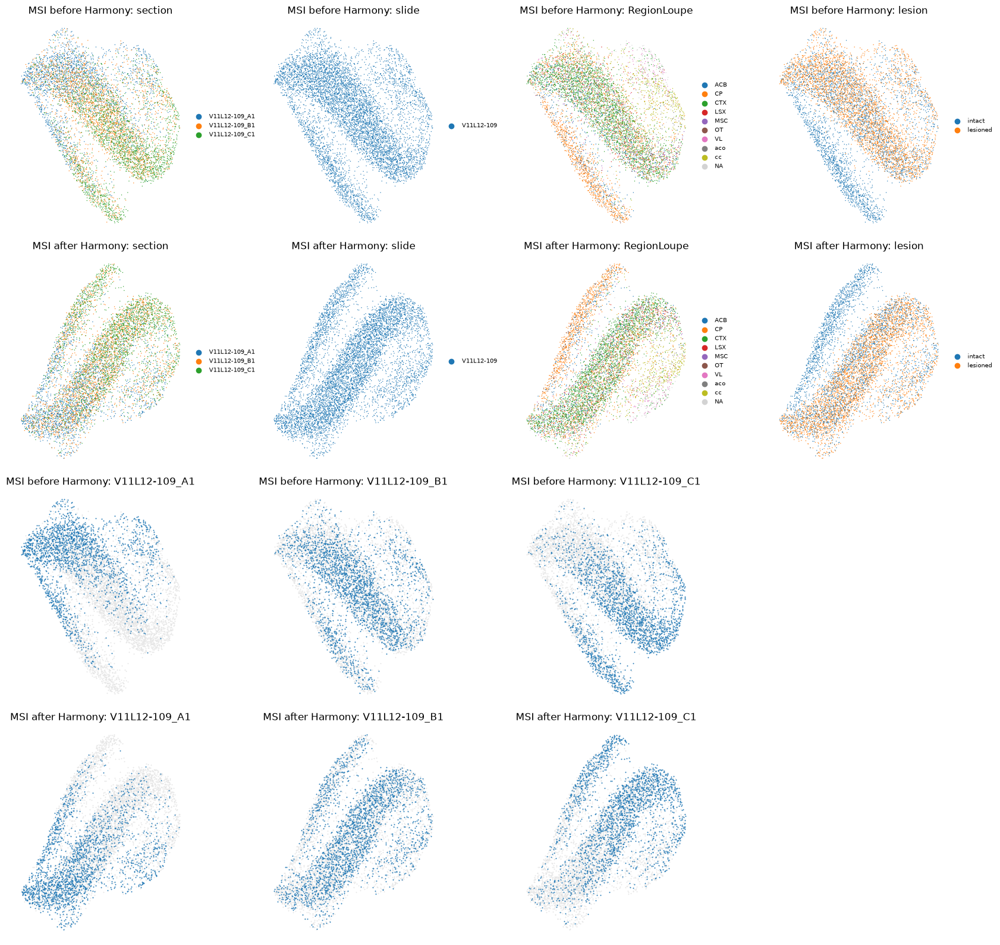

In [11]:
msi_umaps, msi_mixing = {}, {}
msi_sec = msi.obs["section"].astype(str).to_numpy()
for label, rep in {"before Harmony": "X_pca", "after Harmony": "X_pca_harmony"}.items():
    tmp = ad.AnnData(obs=msi.obs[["section", "slide"]].copy(), obsm={rep: msi.obsm[rep]})
    sc.pp.neighbors(tmp, n_neighbors=n_neighbors, use_rep=rep, random_state=seed)
    sc.tl.umap(tmp, random_state=seed)
    g = tmp.obsp["distances"].tocoo()
    msi_mixing[label] = pd.Series(msi_sec[g.row] == msi_sec[g.col]).groupby(msi_sec[g.row]).mean()
    for key in ["RegionLoupe", "lesion"]:
        tmp.obs[key] = mdata.obs[key].reindex(tmp.obs_names).to_numpy()
    msi_umaps[label] = tmp
msi_mixing = pd.DataFrame(msi_mixing)
counts = msi.obs["section"].value_counts()
msi_mixing["expected if mixed within slide"] = counts / counts.groupby(counts.index.str.split("_").str[0]).transform("sum")
display(msi_mixing.round(3).rename_axis("same-section neighbours (MSI)"))

msi_section_list = list(msi.obs["section"].cat.categories) if hasattr(msi.obs["section"], "cat") else sorted(msi.obs["section"].unique())
colour_by = ["section", "slide", "RegionLoupe", "lesion"]
n_cols = max(len(colour_by), len(msi_section_list))
fig, axes = plt.subplots(4, n_cols, figsize=(4.2 * n_cols, 16), squeeze=False)
for row, (label, tmp) in enumerate(msi_umaps.items()):
    for col in range(n_cols):
        ax = axes[row, col]
        if col < len(colour_by):
            sc.pl.umap(tmp, color=colour_by[col], ax=ax, show=False, size=4, frameon=False,
                       title=f"MSI {label}: {colour_by[col]}", legend_fontsize=7)
        else:
            ax.axis("off")
    # split by section: one panel per section on top of the other sections in grey
    xy = tmp.obsm["X_umap"]
    for col in range(n_cols):
        ax = axes[2 + row, col]
        if col < len(msi_section_list):
            in_sec = (tmp.obs["section"] == msi_section_list[col]).to_numpy()
            ax.scatter(xy[~in_sec, 0], xy[~in_sec, 1], s=2, c="#e5e5e5", linewidth=0)
            ax.scatter(xy[in_sec, 0], xy[in_sec, 1], s=2, c="#1f77b4", linewidth=0)
            ax.set_title(f"MSI {label}: {msi_section_list[col]}")
        ax.axis("off")
fig.tight_layout()
fig.savefig(out_dir / "msi_umap_harmony.png", dpi=200)
plt.show()

## Dopamine signal: m/z 674.28833 with tissue-specific gene and cell type

As in Vicari et al. 2024: the FMP-10 MSI peak m/z 674.28833 (dopamine, used by COSIE for the dopamine pattern), together with a gene and a cell-type proportion per tissue (`MARKERS`):
- **striatum**: *Pcp4* and MSN1 (striatal medium spiny neurons, Zeisel et al. 2018); dopamine is found in the dopaminergic terminals of the striatum (CP).
- **substantia nigra**: *Th* (tyrosine hydroxylase, dopamine synthesis) and MBDOP2 (midbrain dopaminergic neurons).

With `DATASET = "all"` the markers of both tissues are shown as rows. Cell-type proportions come from the stereoscope deconvolution of the original study (`misc/Zeisel_stsc_output.csv`). Its spots are labelled with a sample index; indices 5–12 match the sections V11L12-109 A1–D1 and V11T16-085 A1–D1 (identical tissue barcodes). Colour scales are shared across sections (0 to the 99th percentile); D1 has no MSI.

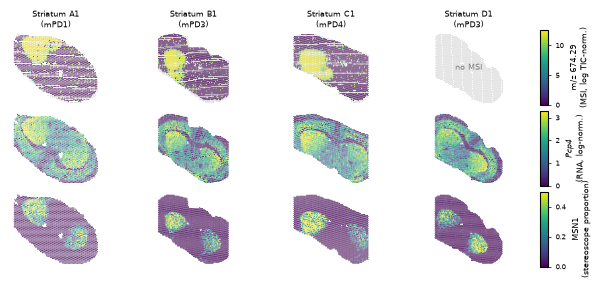

In [12]:
mz_dopamine = "674.28833"
# gene and cell type (title -> column in Zeisel_stsc_output.csv) shown with the dopamine peak, per tissue
MARKERS = {
    "striatum": {"genes": ["Pcp4"], "celltypes": {"MSN1": "Telencephalon.projecting.inhibitory.neurons.MSN1"}},
    "substantia_nigra": {"genes": ["Th"], "celltypes": {"MBDOP2": "Cholinergic.and.monoaminergic.neurons.MBDOP2"}},
}
tissues = list(dict.fromkeys(SLIDES[s]["tissue"] for s in slides))
marker_genes = list(dict.fromkeys(g for t in tissues for g in MARKERS[t]["genes"]))
marker_celltypes = {k: v for t in tissues for k, v in MARKERS[t]["celltypes"].items()}

# stereoscope proportions of the original study; barcode suffix = sample index, 5-12 = the two FMP-10 slides
stsc = pd.read_csv(data_dir / "misc" / "Zeisel_stsc_output.csv", index_col=0, usecols=lambda c: c in ("", *marker_celltypes.values()) or c.startswith("Unnamed"))
stsc_index = {i: s for i, s in zip(range(5, 13), ["V11L12-109_A1", "V11L12-109_B1", "V11L12-109_C1", "V11L12-109_D1",
                                                   "V11T16-085_A1", "V11T16-085_B1", "V11T16-085_C1", "V11T16-085_D1"])}
bc, idx = stsc.index.str.rsplit("_", n=1).str[0], stsc.index.str.rsplit("_", n=1).str[1].astype(int)
stsc = stsc[np.isin(idx, list(stsc_index))]
stsc.index = [f"{stsc_index[i]}_{b}" for b, i in zip(bc[np.isin(idx, list(stsc_index))], idx[np.isin(idx, list(stsc_index))])]


def dense(x):
    return np.asarray(x.todense()).ravel() if sp.issparse(x) else np.asarray(x).ravel()


panels = {
    f"m/z {float(mz_dopamine):.2f}\n(MSI, log TIC-norm.)": pd.Series(dense(msi[:, mz_dopamine].layers["lognorm"]), index=msi.obs_names),
    **{f"$\\it{{{g}}}$\n(RNA, log-norm.)": pd.Series(dense(rna[:, g].X), index=rna.obs_names) for g in marker_genes},
    **{f"{t}\n(stereoscope proportion)": stsc[c] for t, c in marker_celltypes.items()},
}

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 6, "axes.titlesize": 6, "pdf.fonttype": 42})
mm = 1 / 25.4
TISSUE_ABBR = {"striatum": "Striatum", "substantia_nigra": "SN"}
sections = list(SECTIONS)
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])
fig, axes = plt.subplots(len(panels), len(sections) + 1, figsize=(183 * mm, 26 * mm * len(panels)),
                         gridspec_kw={"width_ratios": [1] * len(sections) + [0.06], "wspace": 0.05, "hspace": 0.08})
for row, (label, values) in enumerate(panels.items()):
    vmax = values.quantile(0.99)
    for col, section in enumerate(sections):
        ax = axes[row, col]
        spots = mdata.obs_names[mdata.obs["section"] == section]
        vals = values.reindex(spots)
        shown = vals.dropna().index
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=0.5, c="#e5e5e5", linewidth=0, rasterized=True)
        sc_ = ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=0.5, c=vals[shown], cmap="viridis",
                         vmin=0, vmax=vmax, linewidth=0, rasterized=True)
        ax.set_aspect(1)
        ax.invert_yaxis()
        ax.axis("off")
        if len(shown) == 0:
            ax.text(0.5, 0.5, "no MSI", transform=ax.transAxes, ha="center", va="center", color="#808080")
        if row == 0:
            slide_name, sec = section.split("_")
            ax.set_title(f"{TISSUE_ABBR[SLIDES[slide_name]['tissue']]} {sec}\n({SECTIONS[section][0]})", pad=2)
    cbar = fig.colorbar(sc_, cax=axes[row, -1])
    cbar.set_label(label, fontsize=5.5)
    axes[row, -1].tick_params(labelsize=5, width=0.5, length=2)
fig_name = "_".join(["dopamine_msi", *marker_genes, *marker_celltypes]).lower()  # e.g. dopamine_msi_pcp4_msn1
fig.savefig(out_dir / f"{fig_name}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / f"{fig_name}.png", dpi=300, bbox_inches="tight")
plt.show()

# Save

In [13]:
mdata.write(out_file)
print("written:", out_file)

written: ../results/Cosie_Clustering/striatum/msi_log/mouse_brain_6OHDA_striatum.h5mu


# SpatialLeiden: RNA, MSI, RNA + MSI and RNA + smoothed RNA

Each run combines one or both modality graphs with the spatial graph (`multiplex_leiden`, same resolution and layer weights for all runs). All spots of the sections with MALDI (A1–C1) are clustered: the ~18 % of spots without an MSI value have no edges in the MSI layer and get their label through the spatial (and RNA) layer, as in mosaic clustering. Scores are computed only on spots with MSI, so the three runs are compared on measured spots. Cluster colours are assigned per run and are not comparable between columns.

**RNA + smoothed RNA** is a control without any MSI: a second RNA layer built from the RNA PCs averaged over every spot and two rings of spatial neighbours (next cell). It tests how much of the lesion separation that MSI gives can already be obtained from spatially smoothed RNA.

In [14]:
# smoothed RNA layer (no MSI): RNA PCs averaged over every spot and n_rings_smooth rings of spatial neighbours,
# then a kNN graph. The spatial graph has no edges
# between sections, so the averaging stays within a section.
n_rings_smooth = 2
smoother = sp.identity(mdata.n_obs) + (mdata.obsp["spatial_connectivities"] > 0).astype(float)
smoother = sp.diags(1 / np.asarray(smoother.sum(axis=1)).ravel()) @ smoother
X_smooth = pd.DataFrame(mdata.mod["rna"].obsm[rna_rep], index=mdata.mod["rna"].obs_names).loc[mdata.obs_names].to_numpy()
for _ in range(n_rings_smooth):
    X_smooth = smoother @ X_smooth
smoothed = ad.AnnData(obs=pd.DataFrame(index=mdata.obs_names), obsm={"X_smoothed": StandardScaler().fit_transform(X_smooth)})
sc.pp.neighbors(smoothed, n_neighbors=n_neighbors, use_rep="X_smoothed", random_state=seed)
mdata.obsp["rna_smoothed_connectivities"] = smoothed.obsp["connectivities"]
print("smoothed RNA graph:", mdata.obsp["rna_smoothed_connectivities"].shape)

smoothed RNA graph: (11730, 11730)


In [15]:
# run -> layer -> (resolution, layer weight); tune each run separately, e.g. to get the same number of clusters
# the spatial layer is weighted 0.5 by default, so that it smooths the clusters without dominating them
RUNS = {
    "RNA": {
        "rna": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "MSI": {
        "msi": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + MSI": {
        "rna": (1.0, 1.0),
        "msi": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + smoothed RNA": {  # control without MSI: does the smoothed RNA alone separate the lesion?
        "rna": (1.0, 1.0),
        "rna_smoothed": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + MSI + smoothed RNA": {
        "rna": (1.0, 1.0),
        "msi": (1.0, 1.0),
        "rna_smoothed": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
}
sl_kwargs = {"directed": False, "n_iterations": 5, "random_state": seed}

# all spots of the sections with MALDI; spots without an MSI value have no edges in the MSI layer
# and get their label through the spatial (and RNA) layer
keep = mdata.obs["section"].isin(msi_sections).to_numpy()
sub_obs = mdata.obs[keep]
graphs = {name: mdata.obsp[f"{name}_connectivities"][keep][:, keep] for name in ["rna", "msi", "spatial", "rna_smoothed"]}

# scores only on spots that have MSI, so the three runs are compared on measured spots
annotated = sub_obs["has_msi"] & sub_obs["RegionLoupe"].notna() & sub_obs["lesion"].notna()
# the 6-OHDA lesion acts on the dopaminergic system (striatum: CP, midbrain: VTA-SNc), so it is also scored there only
annotated_cp = annotated & sub_obs["in_lesion_region"]


def run_spatialleiden(params):
    return multiplex_leiden(
        *[graphs[layer] for layer in params],
        partition_kwargs=[{"resolution_parameter": res} for res, _ in params.values()],
        layer_weights=[weight for _, weight in params.values()],
        **sl_kwargs,
    )


def score_runs(runs, labels):
    return pd.DataFrame({
        run: {
            "n_clusters": labels[run].nunique(),
            "ARI RegionLoupe": adjusted_rand_score(sub_obs.loc[annotated, "RegionLoupe"], labels.loc[annotated, run]),
            "ARI lesion": adjusted_rand_score(sub_obs.loc[annotated, "lesion"], labels.loc[annotated, run]),
            f"ARI lesion in {lesion_label}": adjusted_rand_score(sub_obs.loc[annotated_cp, "lesion"], labels.loc[annotated_cp, run]),
            "parameters": ", ".join(f"{layer} r={res:g} w={weight:g}" for layer, (res, weight) in params.items()),
        }
        for run, params in runs.items()
    }).T


sl_labels = pd.DataFrame({run: run_spatialleiden(p) for run, p in RUNS.items()}, index=sub_obs.index).astype("category")
sl_scores = score_runs(RUNS, sl_labels)
sl_scores

,n_clusters,ARI RegionLoupe,ARI lesion,ARI lesion in CP,parameters
RNA,10,0.532797,0.003038,0.00036,"rna r=1 w=1, spatial r=1 w=0.5"
MSI,11,0.12308,0.09016,0.579398,"msi r=1 w=1, spatial r=1 w=0.5"
RNA + MSI,9,0.459529,0.108013,0.795842,"rna r=1 w=1, msi r=1 w=1, spatial r=1 w=0.5"
RNA + smoothed RNA,13,0.315333,0.088874,0.81222,"rna r=1 w=1, rna_smoothed r=1 w=1, spatial r=1..."
RNA + MSI + smoothed RNA,8,0.331552,0.126099,0.756378,"rna r=1 w=1, msi r=1 w=1, rna_smoothed r=1 w=1..."


## Same number of clusters for every run

ARI depends on the number of clusters, so for a fair comparison all runs are brought to `n_clusters_target` (default: the 9 annotated regions + 1, because the lesioned side of `lesion_region` is expected as its own domain). For every combination of layer weights (modality layers from `weight_grid`, the spatial layer from the lower `spatial_weight_grid`), one resolution shared by all layers is bisected until the run has exactly that many clusters; among the combinations that reach it, the one with the highest ARI against `select_by` is kept (default: regions with only `lesion_region` split by lesion side, where the 6-OHDA lesion acts), written to `RUNS` and reclustered. All tested combinations are written to `spatialleiden_<n>_clusters_<select_by>.csv`. Parameters chosen with the annotation are an upper bound on what each modality can achieve, not an unbiased estimate.

In [16]:
n_clusters_target = N_CLUSTERS_TARGET.get(DATASET) or sub_obs.loc[annotated, "RegionLoupe"].nunique() + len(LESION_REGION)
# ARI that decides between weight combinations: "RegionLoupe", "lesion" (whole hemisphere), "region+lesion"
# (every region split by side) or "region+local lesion" (regions, only lesion_region split by side, where the lesion acts)
select_by = "region+local lesion"
weight_grid = [0.5, 1.0, 2.0]  # weights of further modality layers, relative to the first layer of a run
spatial_weight_grid = [0.25, 0.5]  # spatial layer kept weaker; add 1.0 if MSI-only runs become too noisy


def resolution_for(weights, n_target, lo=0.01, hi=5.0, max_iter=15):
    # bisect one resolution shared by all layers until the clustering has n_target clusters
    for _ in range(max_iter):
        mid = (lo + hi) / 2
        labels = run_spatialleiden({layer: (mid, w) for layer, w in weights.items()})
        n = len(np.unique(labels))
        if n == n_target:
            return mid
        lo, hi = (mid, hi) if n < n_target else (lo, mid)
    return None


if select_by == "region+lesion":
    truth = sub_obs["RegionLoupe"].astype(str) + "_" + sub_obs["lesion"].astype(str)
elif select_by == "region+local lesion":
    region = sub_obs["RegionLoupe"].astype(str)
    truth = region.where(~sub_obs["in_lesion_region"], region + "_" + sub_obs["lesion"].astype(str))
else:
    truth = sub_obs[select_by]
truth = truth[annotated].to_numpy()

records = []
for run, params in RUNS.items():
    layers = [layer for layer in params if layer != "spatial"]
    for modality_weights, w_spatial in itertools.product(
        itertools.product(weight_grid, repeat=len(layers) - 1), spatial_weight_grid
    ):
        weights = {**dict(zip(layers, (1.0, *modality_weights))), "spatial": w_spatial}
        res = resolution_for(weights, n_clusters_target)
        if res is None:
            continue
        labels = run_spatialleiden({layer: (res, w) for layer, w in weights.items()})
        records.append({
            "run": run,
            "resolution": res,
            **{f"w_{layer}": w for layer, w in weights.items()},
            "ARI": adjusted_rand_score(truth, labels[annotated.to_numpy()]),
        })
fixed_k = pd.DataFrame(records)
fixed_k.to_csv(out_dir / f"spatialleiden_{n_clusters_target}_clusters_{select_by}.csv", index=False)
missing = set(RUNS) - set(fixed_k["run"])
assert not missing, f"no parameters found that give {n_clusters_target} clusters for {missing}"
best = fixed_k.loc[fixed_k.groupby("run", sort=False)["ARI"].idxmax()].set_index("run")

# take over the best parameters and recluster with them
RUNS = {
    run: {layer: (float(best.loc[run, "resolution"]), float(best.loc[run, f"w_{layer}"])) for layer in params}
    for run, params in RUNS.items()
}
sl_labels = pd.DataFrame({run: run_spatialleiden(p) for run, p in RUNS.items()}, index=sub_obs.index).astype("category")
sl_scores = score_runs(RUNS, sl_labels)
sl_scores

,n_clusters,ARI RegionLoupe,ARI lesion,ARI lesion in CP,parameters
RNA,21,0.256749,0.017925,0.192588,"rna r=2.34906 w=1, spatial r=2.34906 w=0.5"
MSI,21,0.076159,0.044654,0.30472,"msi r=1.55963 w=1, spatial r=1.55963 w=0.25"
RNA + MSI,21,0.269245,0.0476,0.54415,"rna r=2.11516 w=1, msi r=2.11516 w=0.5, spatia..."
RNA + smoothed RNA,21,0.2609,0.027034,0.25162,"rna r=1.97871 w=1, rna_smoothed r=1.97871 w=0...."
RNA + MSI + smoothed RNA,21,0.281447,0.060499,0.603018,"rna r=2.03719 w=1, msi r=2.03719 w=0.5, rna_sm..."


## Manual parameters

Set the resolution and the weight of every layer by hand, per run. `MANUAL_RUNS` uses the same format as `RUNS` (layer → (resolution, layer weight)); listed runs replace the default or tuned parameters, unlisted runs keep theirs, and a new run name adds a run (layers: `rna`, `msi`, `rna_smoothed`, `spatial`). Run this cell after the tuning cell or instead of it; only the listed runs are reclustered. With manual parameters, runs no longer have the same number of clusters (see `n_clusters` in the table).

In [17]:
# run -> layer -> (resolution, layer weight); empty = keep RUNS as it is
MANUAL_RUNS = {
     "RNA": {"rna": (1.2, 1.0), "spatial": (0.8, 0.8)},
     "MSI": {"msi": (1.2, 1.0), "spatial": (.8, .6)},
     "RNA + MSI": {"rna": (1.2, 1.0), "msi": (1.5, 1.0), "spatial": (0.8, 0.5)},
     "RNA + MSI + smoothed RNA": {"rna": (1.0, 1.0), "msi": (1.0, 0.5), "rna_smoothed": (0.7, 0.5), "spatial": (1.0, 0.25)},
}
RUNS = {**RUNS, **MANUAL_RUNS}
for run in RUNS:
    if run in MANUAL_RUNS or run not in sl_labels:
        sl_labels[run] = pd.Categorical(run_spatialleiden(RUNS[run]))
sl_labels = sl_labels[list(RUNS)]

display(pd.DataFrame({run: {layer: f"r={r:g}, w={w:g}" for layer, (r, w) in params.items()}
                      for run, params in RUNS.items()}).T.fillna("–"))
sl_scores = score_runs(RUNS, sl_labels)
sl_scores

,rna,spatial,msi,rna_smoothed
RNA,"r=1.2, w=1","r=0.8, w=0.8",–,–
MSI,–,"r=0.8, w=0.6","r=1.2, w=1",–
RNA + MSI,"r=1.2, w=1","r=0.8, w=0.5","r=1.5, w=1",–
RNA + smoothed RNA,"r=1.97871, w=1","r=1.97871, w=0.25",–,"r=1.97871, w=0.5"
RNA + MSI + smoothed RNA,"r=1, w=1","r=1, w=0.25","r=1, w=0.5","r=0.7, w=0.5"


,n_clusters,ARI RegionLoupe,ARI lesion,ARI lesion in CP,parameters
RNA,9,0.455621,0.010395,0.027746,"rna r=1.2 w=1, spatial r=0.8 w=0.8"
MSI,8,0.138843,0.097449,0.607259,"msi r=1.2 w=1, spatial r=0.8 w=0.6"
RNA + MSI,10,0.37076,0.108779,0.803996,"rna r=1.2 w=1, msi r=1.5 w=1, spatial r=0.8 w=0.5"
RNA + smoothed RNA,21,0.2609,0.027034,0.25162,"rna r=1.97871 w=1, rna_smoothed r=1.97871 w=0...."
RNA + MSI + smoothed RNA,9,0.465309,0.093045,0.916855,"rna r=1 w=1, msi r=1 w=0.5, rna_smoothed r=0.7..."


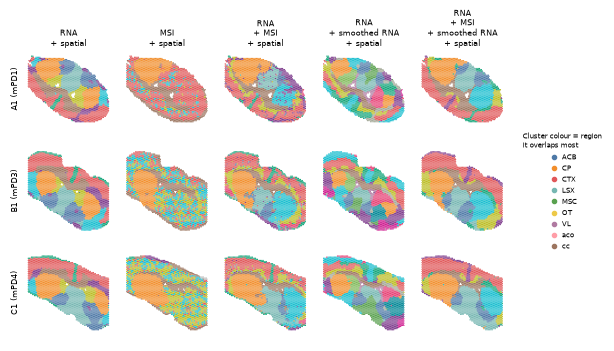

In [18]:
# Clusters of RNA, MSI and RNA + MSI (each with the spatial graph) next to the annotation, to be compared by eye.
# Every cluster gets the colour of the region it overlaps most; if several clusters share a region, the largest
# keeps the region colour and the others get own colours. Only the region x lesion annotation is shaded.

# ---- manual settings: leave empty / None for the automatic choice ----
FIG_SECTIONS = None          # sections (rows), e.g. ["V11T16-085_A1", "V11T16-085_C1"]; None = all sections with MSI
FIG_RUNS = None              # runs (columns), e.g. ["RNA", "RNA + MSI + smoothed RNA"]; None = all runs in RUNS
RUN_TITLES = {}              # run -> column title, e.g. {"RNA + MSI + smoothed RNA": "RNA + MSI\n+ smoothed RNA"}
SHOW_ANNOTATION = False      # True = add the two annotation columns (region, region x lesion)
REGION_COLOR_OVERRIDE = {}   # region -> colour, e.g. {"CP": "#E15759", "VTA-SNc": "#000000"}
CLUSTER_COLOR_OVERRIDE = {}  # run -> {cluster: colour}, e.g. {"MSI": {3: "#000000"}}; cluster ids: SHOW_CLUSTER_TABLE = True
EXTRA_COLORS_MANUAL = None   # list of colours for further clusters of a region; None = default list
FIG_WIDTH_MM, ROW_HEIGHT_MM = 183, 33
POINT_SIZE = 0.9
FIG_NAME = "spatialleiden_rna_msi"  # file name in out_dir (pdf + png)
SHOW_CLUSTER_TABLE = False  # True = print cluster ids, majority region and colour (to fill CLUSTER_COLOR_OVERRIDE)
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "legend.fontsize": 5, "pdf.fonttype": 42, "svg.fonttype": "none",
})
REGION_COLORS = ["#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7", "#9C755F"]
EXTRA_COLORS = ["#17BECF", "#BCBD22", "#7F3C8D", "#11A579", "#E73F74", "#80BA5A", "#008695", "#CF1C90", "#A5AA99"]
# more regions than region colours (e.g. substantia nigra): extend with glasbey colours
REGION_COLORS = REGION_COLORS + [c for c in cc.glasbey_category10 if c not in REGION_COLORS + EXTRA_COLORS]
regions = sorted(mdata.obs["RegionLoupe"].dropna().astype(str).unique())
if EXTRA_COLORS_MANUAL is not None:
    EXTRA_COLORS = list(EXTRA_COLORS_MANUAL)
region_color = {**dict(zip(regions, REGION_COLORS)), **REGION_COLOR_OVERRIDE}


def shade(color, lesioned_fraction):
    # 0 = all intact (lighter), 0.5 = region colour, 1 = all lesioned (darker)
    rgb = np.array(to_rgb(color))
    a = (lesioned_fraction - 0.5) * 2 * 0.45
    return to_hex(rgb * (1 - a) if a > 0 else rgb + (1 - rgb) * -a)


def cluster_colors(labels, obs):
    # colour of every cluster: the region it overlaps most (no shading)
    ok = (obs["RegionLoupe"].notna() & obs["lesion"].notna()).to_numpy()
    df = pd.DataFrame({
        "cluster": labels[ok].to_numpy(),
        "region": obs.loc[ok, "RegionLoupe"].astype(str).to_numpy(),
        "lesioned": (obs.loc[ok, "lesion"].astype(str) == "lesioned").to_numpy(),
    })
    counts = pd.crosstab(df["cluster"], df["region"])
    region, size = counts.idxmax(axis=1), counts.max(axis=1)
    # the largest cluster of a region keeps the region colour, further clusters of that region get own colours
    colors, used, extra = {}, set(), itertools.cycle(EXTRA_COLORS)
    for c in size.sort_values(ascending=False).index:
        colors[c] = next(extra) if region[c] in used else region_color[region[c]]
        used.add(region[c])
    return colors, region


fig_sections = FIG_SECTIONS or [s for s in SECTIONS if s in msi_sections]
fig_runs = FIG_RUNS or list(RUNS)
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])

# cluster colours (automatic, then manual overrides) and a table to look up cluster ids for CLUSTER_COLOR_OVERRIDE
colors_per_run, cluster_table = {}, []
for run in fig_runs:
    colors, majority = cluster_colors(sl_labels[run], sub_obs)
    for cl, col in CLUSTER_COLOR_OVERRIDE.get(run, {}).items():
        key = next((k for k in colors if str(k) == str(cl)), cl)
        colors[key] = col
    colors_per_run[run] = colors
    sizes = sl_labels[run].value_counts()
    cluster_table += [{"run": run, "cluster": k, "majority region": majority.get(k), "n_spots": sizes.get(k, 0), "colour": v}
                      for k, v in colors.items()]
cluster_table = pd.DataFrame(cluster_table)
if SHOW_CLUSTER_TABLE:
    display(cluster_table.style.apply(lambda col: [f"background-color: {v}" for v in col], subset=["colour"]))

mm = 1 / 25.4
n_maps = 2 * SHOW_ANNOTATION + len(fig_runs)
fig, axes = plt.subplots(
    len(fig_sections), n_maps + 1, figsize=(FIG_WIDTH_MM * mm, ROW_HEIGHT_MM * mm * len(fig_sections)),
    gridspec_kw={"width_ratios": [1] * n_maps + [0.75], "wspace": 0.12, "hspace": 0.06}, squeeze=False,
)
for row, section_name in enumerate(fig_sections):
    spots = sub_obs.index[sub_obs["section"] == section_name]
    obs = sub_obs.loc[spots]
    region_here = obs["RegionLoupe"].astype(str)
    lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
    panels = [
        ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
        ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                           for r, l in zip(region_here, lesioned_here)]),
    ] * SHOW_ANNOTATION + [
        (RUN_TITLES.get(run, "\n+ ".join(f"{run} + spatial".split(" + "))),
         [colors_per_run[run].get(c, "#bdbdbd") for c in sl_labels.loc[spots, run]])
        for run in fig_runs
    ]
    for col, (title, colors) in enumerate(panels):
        ax = axes[row, col]
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=colors, linewidth=0, rasterized=True)
        ax.set_aspect(1)
        ax.invert_yaxis()
        ax.axis("off")
        if row == 0:
            ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
    slide_name, sec = section_name.split("_")
    row_label = f"{sec} ({obs['mouse'].iloc[0]})" if len(slides) == 1 else f"{SLIDES[slide_name]['tissue'].replace('_', ' ')}\n{sec} ({obs['mouse'].iloc[0]})"
    axes[row, 0].text(-0.06, 0.5, row_label,
                      transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
    axes[row, -1].axis("off")

shown_regions = sorted(set(sub_obs.loc[sub_obs["section"].isin(fig_sections), "RegionLoupe"].dropna().astype(str)))
axes[len(fig_sections) // 2, -1].legend(
    handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in shown_regions]
    + ([plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
        for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]] if SHOW_ANNOTATION else []),
    loc="center left", frameon=False, handletextpad=0.1, title_fontsize=5,
    title="Region (annotation shaded:\nlight = intact, dark = lesioned)" if SHOW_ANNOTATION
    else "Cluster colour = region\nit overlaps most",
)
fig.savefig(out_dir / f"{FIG_NAME}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / f"{FIG_NAME}.png", dpi=300, bbox_inches="tight")
plt.show()

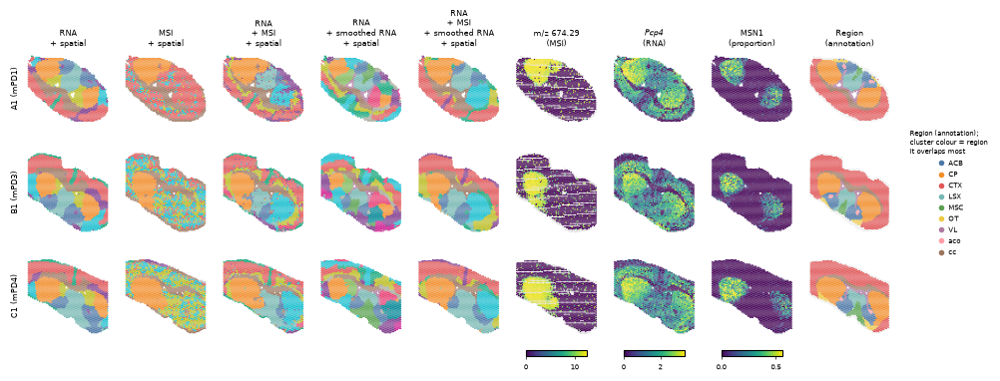

In [19]:
# Cluster maps (from the cell above) and, next to them in the same figure, the dopamine MSI peak, genes and
# cell-type proportions for the same sections. Uses colors_per_run / fig_sections / fig_runs from the cell above
# and stsc / dense / mz_dopamine / marker_genes / marker_celltypes from the dopamine cell. Feature colour scales are shared across rows.

# ---- manual settings ----
FEATURE_GENES = marker_genes                # genes (RNA, log-normalised), e.g. ["Th", "Slc6a3", "Ddc"]
FEATURE_MZ = [mz_dopamine]                  # MSI m/z features, e.g. ["674.28833"]
FEATURE_CELLTYPES = marker_celltypes        # title -> column in Zeisel_stsc_output.csv
FEATURE_CMAP = "viridis"
COMBINED_FIG_NAME = "spatialleiden_rna_msi_with_features"
# annotation columns after the features: "region" and/or "region x lesion" (shaded: light = intact, dark = lesioned)
END_ANNOTATION = ["region"]

features = {
    **{f"m/z {float(m):.2f}\n(MSI)": pd.Series(dense(msi[:, m].layers["lognorm"]), index=msi.obs_names) for m in FEATURE_MZ},
    **{f"$\\it{{{g}}}$\n(RNA)": pd.Series(dense(rna[:, g].X), index=rna.obs_names) for g in FEATURE_GENES},
    **{f"{t}\n(proportion)": stsc[c] for t, c in FEATURE_CELLTYPES.items()},
}
fig_spots = sub_obs.index[sub_obs["section"].isin(fig_sections)]
vmax = {title: values.reindex(fig_spots).quantile(0.99) for title, values in features.items()}

mm = 1 / 25.4
n_cluster_maps = 2 * SHOW_ANNOTATION + len(fig_runs)
n_end = len(END_ANNOTATION)
n_cols = n_cluster_maps + len(features) + n_end + 1  # + legend
panel_mm = FIG_WIDTH_MM / (n_maps + 0.75)  # same map size as in the cluster figure
width_ratios = [1] * n_cluster_maps + [1] * len(features) + [1] * n_end + [0.75]
fig, axes = plt.subplots(
    len(fig_sections) + 1, n_cols,
    figsize=(panel_mm * sum(width_ratios) * mm, ROW_HEIGHT_MM * mm * len(fig_sections) + 6 * mm),
    gridspec_kw={"width_ratios": width_ratios, "height_ratios": [1] * len(fig_sections) + [0.06],
                 "wspace": 0.12, "hspace": 0.06}, squeeze=False,
)
for row, section_name in enumerate(fig_sections):
    spots = sub_obs.index[sub_obs["section"] == section_name]
    obs = sub_obs.loc[spots]
    region_here = obs["RegionLoupe"].astype(str)
    lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
    # cluster / annotation maps: (title, colours)
    maps = [
        ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
        ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                           for r, l in zip(region_here, lesioned_here)]),
    ] * SHOW_ANNOTATION + [
        (RUN_TITLES.get(run, "\n+ ".join(f"{run} + spatial".split(" + "))),
         [colors_per_run[run].get(c, "#bdbdbd") for c in sl_labels.loc[spots, run]])
        for run in fig_runs
    ]
    for col, (title, colors) in enumerate(maps):
        ax = axes[row, col]
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=colors, linewidth=0, rasterized=True)
        if row == 0:
            ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
    # feature maps
    for j, (title, values) in enumerate(features.items()):
        ax = axes[row, n_cluster_maps + j]
        vals = values.reindex(spots)
        shown = vals.dropna().index
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c="#e5e5e5", linewidth=0, rasterized=True)
        sc_ = ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=POINT_SIZE, c=vals[shown], cmap=FEATURE_CMAP,
                         vmin=0, vmax=vmax[title], linewidth=0, rasterized=True)
        if row == 0:
            ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
        if row == len(fig_sections) - 1:  # colour bar below the last row
            cax = axes[-1, n_cluster_maps + j]
            pos = cax.get_position()
            cax.set_position([pos.x0 + pos.width * 0.15, pos.y0, pos.width * 0.7, pos.height])
            fig.colorbar(sc_, cax=cax, orientation="horizontal").ax.tick_params(labelsize=5, width=0.5, length=2)
    # annotation after the features
    end_maps = {
        "region": ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
        "region x lesion": ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                                               for r, l in zip(region_here, lesioned_here)]),
    }
    for j, key in enumerate(END_ANNOTATION):
        title, colors = end_maps[key]
        ax = axes[row, n_cluster_maps + len(features) + j]
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=colors, linewidth=0, rasterized=True)
        if row == 0:
            ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
    for ax in axes[row, :-1]:
        ax.set_aspect(1)
        ax.invert_yaxis()
        ax.axis("off")
    slide_name, sec = section_name.split("_")
    row_label = f"{sec} ({obs['mouse'].iloc[0]})" if len(slides) == 1 else f"{SLIDES[slide_name]['tissue'].replace('_', ' ')}\n{sec} ({obs['mouse'].iloc[0]})"
    axes[row, 0].text(-0.06, 0.5, row_label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
    axes[row, -1].axis("off")
for ax in [*axes[-1, :n_cluster_maps], *axes[-1, n_cluster_maps + len(features):]]:
    ax.axis("off")
axes[-1, -1].axis("off")

axes[len(fig_sections) // 2, -1].legend(
    handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in shown_regions]
    + ([plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
        for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]]
       if SHOW_ANNOTATION or "region x lesion" in END_ANNOTATION else []),
    loc="center left", frameon=False, handletextpad=0.1, title_fontsize=5,
    title="Region (annotation shaded:\nlight = intact, dark = lesioned)" if SHOW_ANNOTATION or "region x lesion" in END_ANNOTATION
    else "Region (annotation);\ncluster colour = region\nit overlaps most",
)
fig.savefig(out_dir / f"{COMBINED_FIG_NAME}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / f"{COMBINED_FIG_NAME}.png", dpi=300, bbox_inches="tight")
plt.show()

# Multisample / multimodal clustering without integration

All sections that a run can use are clustered **in one `multiplex_leiden` call**, so a cluster label means the same thing in every section. There is no batch correction: the RNA and MSI kNN graphs are built on one PCA over all sections (preprocessing above), and the spatial graph has no edges between sections. Each run uses only the sections in which all its modalities are measured: RNA on A1–D1, MSI and RNA + MSI on A1–C1. Parameters are taken from `RUNS` (default or tuned in the cell above).

- The first table shows how well the sections mix without integration: the share of kNN neighbours from the spot's own section, compared with the share expected under perfect mixing.
- Scores: ARI per section and pooled over all clustered sections (`all`), on all annotated spots (incl. spots without MSI). A pooled ARI below the per-section ARIs means the same cluster is used for different regions in different sections.

In [20]:
all_sections = list(SECTIONS)
msi_section_names = [s for s in SECTIONS if s in msi_sections]
score_spots = mdata.obs["RegionLoupe"].notna() & mdata.obs["lesion"].notna()
section_of = mdata.obs["section"].astype(str).to_numpy()


def neighbour_mixing(name):
    # share of a spot's kNN neighbours that come from its own section, and what it would be with perfect mixing
    graph = mdata.obsp[f"{name}_connectivities"]
    g = graph.tocoo()
    measured = np.asarray(graph.sum(axis=1)).ravel() > 0
    return pd.DataFrame({
        (name, "same section"): pd.Series(section_of[g.row] == section_of[g.col]).groupby(section_of[g.row]).mean(),
        (name, "if mixed"): pd.Series(section_of[measured]).value_counts(normalize=True),
    })


display(pd.concat([neighbour_mixing(name) for name in ["rna", "msi"]], axis=1).round(2))


def cluster_sections(params, sections):
    # one multiplex_leiden call over all spots of the given sections; returns one shared label per spot
    keep = mdata.obs["section"].isin(sections).to_numpy()
    labels = multiplex_leiden(
        *[mdata.obsp[f"{layer}_connectivities"][keep][:, keep] for layer in params],
        partition_kwargs=[{"resolution_parameter": res} for res, _ in params.values()],
        layer_weights=[weight for _, weight in params.values()],
        **sl_kwargs,
    )
    return pd.Series(labels, index=mdata.obs_names[keep]).astype("category")


def score_by_section(labels):
    # ARI per section and pooled over all clustered sections ("all"), on all annotated spots
    obs = mdata.obs.loc[labels.index].assign(cluster=labels)
    obs = obs[score_spots[labels.index]]
    groups = {"all": obs, **dict(list(obs.groupby(obs["section"].astype(str))))}
    return pd.DataFrame({
        name: {
            "n_clusters": g["cluster"].nunique(),
            "ARI region": adjusted_rand_score(g["RegionLoupe"], g["cluster"]),
            "ARI lesion": adjusted_rand_score(g["lesion"], g["cluster"]),
        }
        for name, g in groups.items()
    }).T


# run -> (layer parameters from RUNS above, sections); every run only on sections where all its modalities exist
JOINT_RUNS = {
    "RNA": (RUNS["RNA"], all_sections),
    "MSI": (RUNS["MSI"], msi_section_names),
    "RNA + MSI": (RUNS["RNA + MSI"], msi_section_names),
}
joint_labels = {run: cluster_sections(params, sections) for run, (params, sections) in JOINT_RUNS.items()}
joint_scores = pd.concat({run: score_by_section(labels) for run, labels in joint_labels.items()})
joint_scores.astype(float).unstack().round(2)

rna                   msi         
              same section if mixed same section if mixed
V11L12-109_A1         0.21     0.23         0.54     0.31
V11L12-109_B1         0.22     0.27         0.41     0.36
V11L12-109_C1         0.26     0.25         0.47     0.33
V11L12-109_D1         0.34     0.26          NaN      NaN

n_clusters                                                  \
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all   
RNA                10.0          10.0          10.0          10.0  10.0   
MSI                 5.0           5.0           7.0           NaN   7.0   
RNA + MSI          10.0          10.0          10.0           NaN  10.0   

             ARI region                                                  \
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all   
RNA                0.59          0.48          0.52          0.46  0.50   
MSI                0.16          0.14          0.13           NaN  0.14   
RNA + MSI          0.38          0.39          0.38           NaN  0.38   

             ARI lesion                                                  
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all  
RNA                0.00          0.00          0.02          0.01  0.00  
MSI                0.15          0.09          0.12           NaN  0.10  
RNA + MSI          0.10          0.09          0.15           NaN  0.11

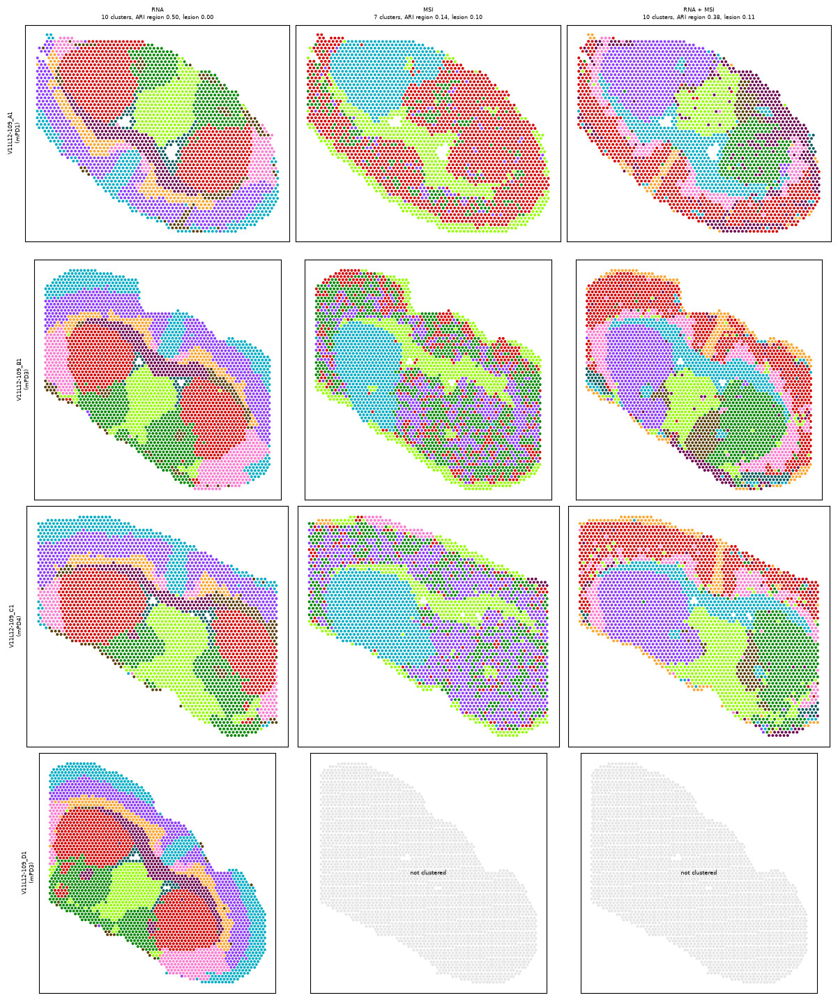

In [21]:
def plot_runs(labels, file_name):
    # rows = sections, columns = runs; colours are per run but shared across sections, so the same colour
    # in two sections of one column is the same cluster
    xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])
    fig, axes = plt.subplots(
        len(all_sections), len(labels), figsize=(4 * len(labels), 3.6 * len(all_sections)), squeeze=False
    )
    for col, (run, lab) in enumerate(labels.items()):
        palette = dict(zip(lab.cat.categories, cc.glasbey))
        pooled = score_by_section(lab).loc["all"]
        for row, section in enumerate(all_sections):
            ax = axes[row, col]
            spots = mdata.obs_names[mdata.obs["section"] == section]
            shown = spots[spots.isin(lab.index)]
            if len(shown):
                ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=8, c=lab[shown].map(palette).tolist(),
                           linewidth=0, rasterized=True)
            else:
                ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=8, c="#e5e5e5", linewidth=0, rasterized=True)
                ax.text(0.5, 0.5, "not clustered", transform=ax.transAxes, ha="center", va="center")
            ax.set(aspect=1, xticks=[], yticks=[])
            ax.invert_yaxis()
            if row == 0:
                ax.set_title(f"{run}\n{pooled['n_clusters']:.0f} clusters, ARI region {pooled['ARI region']:.2f}, "
                             f"lesion {pooled['ARI lesion']:.2f}")
            if col == 0:
                ax.set_ylabel(f"{section}\n({mdata.obs.loc[spots, 'mouse'].iloc[0]})")
    fig.tight_layout()
    fig.savefig(file_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_runs(joint_labels, out_dir / "spatialleiden_joint_no_integration.pdf")

# Mosaic clustering, first run

RNA + MSI + spatial on **all four sections**, D1 included although it has no MSI (the COSIE setting: Section 3 without MSI). D1 spots have no edges in the MSI layer and are connected to the other sections only through the RNA layer and to each other through the spatial layer. Compared with:
- **RNA (A1–D1)**: does D1 profit from the MSI measured in the other sections (mainly ARI lesion in D1)?
- **RNA + MSI (A1–C1)**: does adding a section without MSI hurt the sections with MSI?
- **all**: one ARI over all sections; high only if the same cluster means the same region in every section.

All runs are brought to `n_clusters_mosaic` clusters (shared resolution bisected), so the ARIs are comparable.

**Layer balance.** `multiplex_leiden` sums the modularity of the layers, and a layer's share grows with its total edge weight. Adding D1 doubles the RNA edges (and adds 35 % spatial edges) but no MSI edges, so with equal `layer_weights` RNA dominates and the lesion signal from MSI is lost. `normalize_layers = True` scales every layer by 1 / its total edge weight on the clustered sections, so each layer counts equally whatever number of sections it covers. Compare `True` and `False`, and check the section table: clusters that exist only in D1 or not in D1 mean the mosaic splits spots with and without MSI instead of sharing clusters.

RNA (A1–D1)                             r=1.102, rna w=0.90, spatial w=1.12
RNA + MSI (A1–C1)           r=1.102, rna w=1.30, msi w=0.92, spatial w=0.87
RNA + MSI mosaic (A1–D1)    r=1.184, rna w=0.79, msi w=1.40, spatial w=0.98


n_clusters                              \
                         V11L12-109_A1 V11L12-109_B1 V11L12-109_C1   
RNA (A1–D1)                        9.0           9.0           9.0   
RNA + MSI (A1–C1)                  9.0           9.0           9.0   
RNA + MSI mosaic (A1–D1)           8.0           9.0           9.0   

                                               ARI region                \
                         V11L12-109_D1  all V11L12-109_A1 V11L12-109_B1   
RNA (A1–D1)                        9.0  9.0          0.50          0.43   
RNA + MSI (A1–C1)                  NaN  9.0          0.47          0.41   
RNA + MSI mosaic (A1–D1)           9.0  9.0          0.40          0.37   

                                                              ARI lesion  \
                         V11L12-109_C1 V11L12-109_D1   all V11L12-109_A1   
RNA (A1–D1)                       0.42          0.40  0.43          0.01   
RNA + MSI (A1–C1)                 0.41           NaN  0.42          0.11   
RNA + MSI mosaic (A1–D1)          0.40          0.48  0.39          0.16   

                                                                          
                         V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all  
RNA (A1–D1)                       0.01          0.03          0.01  0.01  
RNA + MSI (A1–C1)                 0.09          0.14           NaN  0.11  
RNA + MSI mosaic (A1–D1)          0.11          0.16          0.02  0.07

section,V11L12-109_A1,V11L12-109_B1,V11L12-109_C1,V11L12-109_D1
row_0,,,,
0,571,626,591,627
1,477,441,559,577
2,67,559,517,413
3,266,407,302,485
4,347,372,338,292
5,255,278,452,287
6,35,345,110,255
7,657,34,16,3
8,0,58,33,78


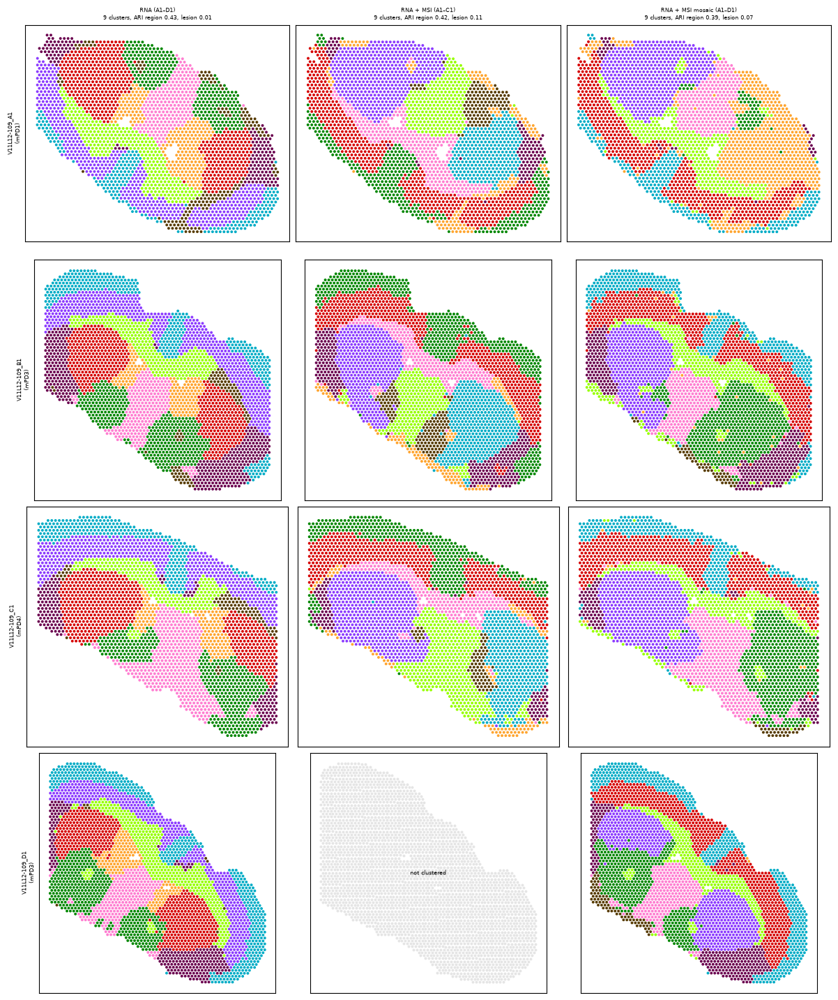

In [22]:
n_clusters_mosaic = mdata.obs["RegionLoupe"].nunique()  # same number of clusters for every run: the annotated regions
normalize_layers = True  # scale each layer by 1 / its total edge weight on the clustered sections

# run -> (layer -> weight before normalisation, sections); one resolution shared by all layers is bisected per run
MOSAIC_RUNS = {
    "RNA (A1–D1)": ({"rna": 1.0, "spatial": 1.0}, all_sections),
    "RNA + MSI (A1–C1)": ({"rna": 1.0, "msi": 1.0, "spatial": 1.0}, msi_section_names),
    "RNA + MSI mosaic (A1–D1)": ({"rna": 1.0, "msi": 1.0, "spatial": 1.0}, all_sections),
}


def effective_weights(weights, sections):
    # a layer's share of the multiplex modularity grows with its total edge weight; a layer that is
    # measured on more sections (RNA, spatial) would otherwise dominate one missing in a section (MSI)
    if not normalize_layers:
        return dict(weights)
    keep = mdata.obs["section"].isin(sections).to_numpy()
    totals = {layer: mdata.obsp[f"{layer}_connectivities"][keep][:, keep].sum() for layer in weights}
    mean_total = np.mean(list(totals.values()))
    return {layer: w * mean_total / totals[layer] for layer, w in weights.items()}


def cluster_at_k(weights, sections, n_target, lo=0.01, hi=5.0, max_iter=20):
    # bisect one resolution shared by all layers until the clustering has n_target clusters
    for _ in range(max_iter):
        res = (lo + hi) / 2
        labels = cluster_sections({layer: (res, w) for layer, w in weights.items()}, sections)
        if labels.nunique() == n_target:
            return labels, res
        lo, hi = (res, hi) if labels.nunique() < n_target else (lo, res)
    raise ValueError(f"no resolution gives {n_target} clusters for weights {weights}")


mosaic_compare, mosaic_params = {}, {}
for run, (weights, sections) in MOSAIC_RUNS.items():
    w = effective_weights(weights, sections)
    mosaic_compare[run], res = cluster_at_k(w, sections, n_clusters_mosaic)
    mosaic_params[run] = f"r={res:.3f}, " + ", ".join(f"{layer} w={v:.2f}" for layer, v in w.items())
mosaic_labels = mosaic_compare["RNA + MSI mosaic (A1–D1)"]

print(pd.Series(mosaic_params).to_string())
mosaic_scores = pd.concat({run: score_by_section(labels) for run, labels in mosaic_compare.items()})
display(mosaic_scores.astype(float).unstack().round(2))

# spots of each mosaic cluster per section: clusters (almost) only in D1 or (almost) absent from D1 mean that
# the mosaic separates spots with and without MSI instead of sharing clusters across sections
display(pd.crosstab(mosaic_labels, mdata.obs.loc[mosaic_labels.index, "section"]))

plot_runs(mosaic_compare, out_dir / f"spatialleiden_mosaic_k{n_clusters_mosaic}{'_normalized' if normalize_layers else ''}.pdf")

## Masking experiment, one section at a time

The MSI of one MALDI section (A1, B1 or C1, in turn) is hidden, and all MALDI sections are clustered together again. D1 (no MSI) is not included. Methods, all with the parameters of the cluster figure above (`RUNS`), so *RNA only* and *Full MSI* are the same clusterings as the columns *RNA* and *RNA + MSI* there:
- *RNA only*: RNA + spatial (`RUNS["RNA"]`), no MSI (lower bound).
- *MSI only*: MSI + spatial (`RUNS["MSI"]`) with the real MSI of all sections (reference, the same clustering in every row).
- *Full MSI*: RNA + MSI + spatial (`RUNS["RNA + MSI"]`) with the real MSI of all sections (reference).
- *Isolated*: as *Full MSI*, but the spots of the masked section have no MSI edges. The MSI kNN graph is rebuilt from the other sections only (PCA refitted on their spots, Harmony if `msi_rep == "X_pca_harmony"`), so the masked section does not influence the MSI embedding.
- *Bridge: …*: as *Isolated*, plus a bridge layer that connects the masked section to the other sections through the part of the RNA variation that is related to MSI (supervised feature projection, no MSI values are predicted; same idea as the bridge in Seurat bridge integration, Hao et al. 2023). A projection between the RNA embedding (`rna_rep`) and the MSI PCs is fitted on the paired spots outside the masked section only; its RNA side is applied to the RNA of all spots, the components are weighted by their correlation on the training spots, and a kNN graph on this projection is the bridge layer (resolution and weight of the MSI layer, `BRIDGE_LAYER`; `bridge_n_components` components). Three established methods from `sklearn.cross_decomposition`: **CCA** (maximises the correlation of the components), **PLSCanonical** (maximises their covariance, symmetric PLS mode A) and **PLSSVD** (SVD of the cross-covariance of the standardised data, the "diagonal CCA" of Seurat v3, Stuart et al. 2019). The ridge CCA (`fit_cca`) is kept as reference. Each sklearn method is fitted on two inputs: **PCs** (`rna_rep` vs MSI PCs) and **genes × m/z** (highly variable genes, log-normalised, vs all m/z; `FEATURE_BRIDGES`). On PCs the three methods nearly coincide, because PCs are already decorrelated within a modality; on genes × m/z they differ (CCA whitens the covariance of thousands of features, PLSCanonical and PLSSVD do not). Diagnostic (not used for clustering): the held-out correlation of the RNA and MSI component scores on the masked section, with its real MSI projected onto the MSI PCs fitted without it.
- Every method is clustered with the seeds in `MASK_SEEDS`; maps use the first seed, the scores table has one row per seed.

No MSI values are imputed. Scores on the annotated spots of the masked section that have MSI (the same spots as in the score tables above; for *Isolated* their MSI is hidden): ARI region, ARI lesion, and ARI lesion within the lesion region. Saved to `masking_per_section_scores.csv`.

In [23]:
MASK_SECTIONS = [s for s in SECTIONS if s in msi_sections]  # sections whose MSI is masked in turn (A1, B1, C1)
MASK_SEEDS = [seed]  # Leiden seeds; maps use the first one; e.g. [seed, seed + 1, seed + 2, seed + 3, seed + 4] for seed variability
# RNA bridge: a projection of RNA (rna_rep) learned together with the MSI PCs on the paired spots outside the masked
# section; its RNA side is applied to all spots and a kNN graph on it is the bridge layer (no MSI values are predicted)
bridge_n_components = 10  # components of every bridge method
bridge_reg = 0.1          # ridge CCA only: ridge added to the covariance matrices, as a fraction of their mean variance
BRIDGE_LAYER = RUNS["RNA + MSI"]["msi"]  # (resolution, weight) of every bridge layer; default: those of the MSI layer


def msi_pca_without(masked_section):
    # PCA of the MSI spots outside masked_section (fitted on them only)
    rest = (msi.obs["section"] != masked_section).to_numpy()
    m = ad.AnnData(msi.X[rest], obs=msi.obs.loc[rest, ["section", "slide"]].copy())
    sc.pp.pca(m, n_comps=n_pcs["msi"], random_state=seed)
    return m


def msi_graph_without(m):
    # MSI kNN graph of the spots in m (from msi_pca_without), padded to the clustered spots;
    # the spots of the masked section have no MSI edges
    m = m.copy()
    if msi_rep == "X_pca_harmony":
        m.obsm["X_pca_harmony"] = m.obsm["X_pca"].copy()
        for slide_name in m.obs["slide"].unique():
            rows = (m.obs["slide"] == slide_name).to_numpy()
            if m.obs.loc[rows, "section"].nunique() < 2:
                continue
            ho = harmonypy.run_harmony(m.obsm["X_pca"][rows], m.obs.loc[rows, ["section"]], "section", random_state=seed, verbose=False)
            Z = np.asarray(ho.Z_corr)
            m.obsm["X_pca_harmony"][rows] = Z if Z.shape[0] == rows.sum() else Z.T
    sc.pp.neighbors(m, n_neighbors=n_neighbors, use_rep=msi_rep, random_state=seed)
    return pad_graph(m.obsp["connectivities"], m.obs_names, sub_obs.index)


def inv_sqrt(C):
    w, V = np.linalg.eigh(C)
    return V @ np.diag(1 / np.sqrt(np.maximum(w, 1e-12))) @ V.T


def fit_cca(X, Y, n_components, reg):
    # regularised (ridge) CCA on paired rows of X and Y (standardised); returns means, sds, weights and correlations
    mx, sx, my, sy = X.mean(0), X.std(0) + 1e-9, Y.mean(0), Y.std(0) + 1e-9
    Xs, Ys = (X - mx) / sx, (Y - my) / sy
    n = len(Xs)
    Cxx, Cyy, Cxy = Xs.T @ Xs / n, Ys.T @ Ys / n, Xs.T @ Ys / n
    Cxx += reg * np.trace(Cxx) / len(Cxx) * np.eye(len(Cxx))
    Cyy += reg * np.trace(Cyy) / len(Cyy) * np.eye(len(Cyy))
    Kx, Ky = inv_sqrt(Cxx), inv_sqrt(Cyy)
    U, s, Vt = np.linalg.svd(Kx @ Cxy @ Ky)
    k = min(n_components, len(s))
    return {"mx": mx, "sx": sx, "my": my, "sy": sy, "Wx": Kx @ U[:, :k], "Wy": Ky @ Vt.T[:, :k], "corr": s[:k]}


def make_sklearn_fit(model):
    # same output as fit_cca for a model from sklearn.cross_decomposition (CCA, PLSCanonical, PLSSVD); inputs are
    # standardised here and passed with scale=False, so the weights apply to standardised data as in fit_cca;
    # the correlation of every component is that of the RNA and MSI scores on the training spots
    def fit(X, Y, n_components, reg=None):
        mx, sx, my, sy = X.mean(0), X.std(0) + 1e-9, Y.mean(0), Y.std(0) + 1e-9
        Xs, Ys = (X - mx) / sx, (Y - my) / sy
        k = min(n_components, X.shape[1], Y.shape[1])
        kwargs = {} if model is PLSSVD else {"max_iter": 1000}
        est = model(n_components=k, scale=False, **kwargs).fit(Xs, Ys)
        Wx = est.x_rotations_ if hasattr(est, "x_rotations_") else est.x_weights_
        Wy = est.y_rotations_ if hasattr(est, "y_rotations_") else est.y_weights_
        u, v = Xs @ Wx, Ys @ Wy
        corr = np.array([np.corrcoef(u[:, i], v[:, i])[0, 1] for i in range(k)])
        return {"mx": mx, "sx": sx, "my": my, "sy": sy, "Wx": Wx, "Wy": Wy, "corr": corr}
    return fit


fit_cca_sklearn = make_sklearn_fit(CCA)
# bridge layer -> (fit function, name); the last three are established methods from sklearn.cross_decomposition:
# CCA (maximises correlation), PLSCanonical (maximises covariance, symmetric PLS mode A) and PLSSVD (SVD of the
# cross-covariance of standardised data, the "diagonal CCA" used by Seurat v3); ridge CCA is kept as reference
CCA_FITS = {
    "rna_bridge": (fit_cca, "ridge CCA"),
    "rna_bridge_sklearn": (fit_cca_sklearn, "CCA"),
    "rna_bridge_plscanonical": (make_sklearn_fit(PLSCanonical), "PLSCanonical"),
    "rna_bridge_plssvd": (make_sklearn_fit(PLSSVD), "PLSSVD"),
}
# input of a bridge: "pca" = RNA embedding (rna_rep) vs MSI PCs; "features" = RNA highly variable genes (log-normalised)
# vs all m/z (msi.X). On PCs the three sklearn methods nearly coincide (PCs are already decorrelated within a modality);
# on the features they differ (CCA whitens the covariance of thousands of features, PLS does not)
FEATURE_BRIDGES = []  # bridges also fitted on genes x m/z, e.g. ["rna_bridge_sklearn", "rna_bridge_plscanonical", "rna_bridge_plssvd"]
FEATURE_SUFFIX = " (genes × m/z)"
# bridge layer -> (fit function, method name, input)
BRIDGES = {
    **{layer: (fit, name, "pca") for layer, (fit, name) in CCA_FITS.items()},
    **{f"{layer}_features": (CCA_FITS[layer][0], CCA_FITS[layer][1] + FEATURE_SUFFIX, "features") for layer in FEATURE_BRIDGES},
}
# method -> layers and parameters (resolution, weight); RNA only / Full MSI / Isolated use the runs of the cluster figure
MASK_METHODS = {
    "RNA only": RUNS["RNA"],
    "MSI only": RUNS["MSI"],
    "Full MSI": RUNS["RNA + MSI"],
    "Isolated": RUNS["RNA + MSI"],
    **{f"Bridge: {name}": {**RUNS["RNA + MSI"], layer: BRIDGE_LAYER} for layer, (_, name, _) in BRIDGES.items()},
}


def to_dense(x):
    return x.toarray() if sp.issparse(x) else np.asarray(x)


# RNA input of the "features" bridges: highly variable genes (log-normalised) of the clustered spots
rna_hvg = pd.DataFrame(to_dense(rna[sub_obs.index, rna.var_names[rna.var["highly_variable"].to_numpy()]].X).astype(float),
                       index=sub_obs.index)


def rna_bridge_graph(m, masked_section, fit=fit_cca, inp="pca"):
    # bridge layer: kNN graph on the RNA of all clustered spots, projected onto the RNA weights of the fitted method
    # (paired spots outside masked_section; inp "pca": rna_rep vs the MSI PCs of m, "features": HVGs vs m/z);
    # components weighted by their correlation on the training spots
    rna_emb = pd.DataFrame(rna.obsm[rna_rep], index=rna.obs_names) if inp == "pca" else rna_hvg
    Y_train = m.obsm["X_pca"] if inp == "pca" else to_dense(m.X).astype(float)
    cca = fit(rna_emb.loc[m.obs_names].to_numpy(), Y_train, bridge_n_components, bridge_reg)
    Z = (rna_emb.loc[sub_obs.index].to_numpy() - cca["mx"]) / cca["sx"] @ cca["Wx"] * cca["corr"]
    a = ad.AnnData(obs=pd.DataFrame(index=sub_obs.index), obsm={"X_bridge": Z})
    sc.pp.neighbors(a, n_neighbors=n_neighbors, use_rep="X_bridge", random_state=seed)
    # diagnostic only: correlation on the masked section (its MSI projected onto the PCs fitted without it)
    held = msi.obs_names[(msi.obs["section"] == masked_section).to_numpy()]
    M = to_dense(msi[held].X).astype(float)
    Yh = (M - np.asarray(m.X.mean(axis=0)).ravel()) @ m.varm["PCs"] if inp == "pca" else M
    u = (rna_emb.loc[held].to_numpy() - cca["mx"]) / cca["sx"] @ cca["Wx"]
    v = (Yh - cca["my"]) / cca["sy"] @ cca["Wy"]
    held_corr = np.array([np.corrcoef(u[:, i], v[:, i])[0, 1] for i in range(u.shape[1])])
    info = {"train corr": cca["corr"], "held-out corr": held_corr}
    return a.obsp["connectivities"], info


def cluster_layers(layer_graphs, params, random_state=seed):
    # multiplex_leiden on the MALDI sections (sub_obs) with the given layers and parameters
    labels = multiplex_leiden(
        *[layer_graphs[layer] for layer in params],
        partition_kwargs=[{"resolution_parameter": res} for res, _ in params.values()],
        layer_weights=[weight for _, weight in params.values()],
        **{**sl_kwargs, "random_state": random_state},
    )
    return pd.Series(labels, index=sub_obs.index).astype("category")


mask_labels, records, bridge_info = {}, [], {}
for masked_section in MASK_SECTIONS:
    m_rest = msi_pca_without(masked_section)
    masked_graphs = {**graphs, "msi": msi_graph_without(m_rest)}
    for layer, (fit, name, inp) in BRIDGES.items():
        masked_graphs[layer], bridge_info[masked_section, name] = rna_bridge_graph(m_rest, masked_section, fit, inp)
    # scored on the annotated spots of the masked section that have MSI (same spots as score_runs above)
    on = annotated & (sub_obs["section"] == masked_section)
    on_lesion_region = on & sub_obs["in_lesion_region"]
    for method, params in MASK_METHODS.items():
        for s in MASK_SEEDS:
            labels = cluster_layers(graphs if method in ("RNA only", "MSI only", "Full MSI") else masked_graphs, params, s)
            if s == MASK_SEEDS[0]:
                mask_labels[masked_section, method] = labels
            records.append({
                "masked section": masked_section, "method": method, "seed": s, "n_clusters": labels.nunique(),
                "ARI region": adjusted_rand_score(sub_obs.loc[on, "RegionLoupe"], labels[on]),
                "ARI lesion": adjusted_rand_score(sub_obs.loc[on, "lesion"], labels[on]),
                f"ARI lesion in {lesion_label}": adjusted_rand_score(sub_obs.loc[on_lesion_region, "lesion"], labels[on_lesion_region]),
                "parameters": ", ".join(f"{layer} r={res:g} w={weight:g}" for layer, (res, weight) in params.items()),
            })
display(pd.DataFrame({key: {"train corr (C1-3)": ", ".join(f"{c:.2f}" for c in d["train corr"][:3]),
                            "held-out corr (C1-3)": ", ".join(f"{c:.2f}" for c in d["held-out corr"][:3])}
                      for key, d in bridge_info.items()}).T.rename_axis(["masked section", "bridge"]))
mask_scores = pd.DataFrame(records)
mask_scores.to_csv(out_dir / "masking_per_section_scores.csv", index=False)
mask_scores.groupby(["masked section", "method"], sort=False)[["n_clusters", "ARI region", "ARI lesion", f"ARI lesion in {lesion_label}"]].mean().round(3)


train corr (C1-3) held-out corr (C1-3)
masked section bridge                                             
V11L12-109_A1  ridge CCA     0.65, 0.61, 0.34     0.65, 0.52, 0.16
               CCA           0.72, 0.67, 0.37     0.65, 0.53, 0.16
               PLSCanonical  0.72, 0.67, 0.37     0.66, 0.50, 0.16
               PLSSVD        0.72, 0.67, 0.37     0.66, 0.50, 0.16
V11L12-109_B1  ridge CCA     0.66, 0.57, 0.33     0.65, 0.63, 0.25
               CCA           0.73, 0.63, 0.37     0.65, 0.63, 0.25
               PLSCanonical  0.72, 0.62, 0.36     0.64, 0.62, 0.25
               PLSSVD        0.72, 0.62, 0.36     0.64, 0.62, 0.25
V11L12-109_C1  ridge CCA     0.62, 0.58, 0.29     0.72, 0.64, 0.26
               CCA           0.69, 0.63, 0.32     0.72, 0.64, 0.26
               PLSCanonical  0.68, 0.63, 0.31     0.72, 0.64, 0.26
               PLSSVD        0.68, 0.63, 0.31     0.72, 0.64, 0.26

n_clusters  ARI region  ARI lesion  \
masked section method                                                     
V11L12-109_A1  RNA only                     9.0       0.494       0.008   
               MSI only                     8.0       0.160       0.150   
               Full MSI                    10.0       0.377       0.102   
               Isolated                    10.0       0.546       0.021   
               Bridge: ridge CCA            9.0       0.480       0.036   
               Bridge: CCA                  9.0       0.449       0.043   
               Bridge: PLSCanonical         9.0       0.457       0.045   
               Bridge: PLSSVD               9.0       0.498       0.018   
V11L12-109_B1  RNA only                     9.0       0.452       0.010   
               MSI only                     8.0       0.140       0.085   
               Full MSI                    10.0       0.377       0.096   
               Isolated                    11.0       0.470       0.004   
               Bridge: ridge CCA           10.0       0.386       0.036   
               Bridge: CCA                  9.0       0.446       0.027   
               Bridge: PLSCanonical        10.0       0.447       0.025   
               Bridge: PLSSVD              10.0       0.426       0.026   
V11L12-109_C1  RNA only                     9.0       0.438       0.033   
               MSI only                     8.0       0.127       0.121   
               Full MSI                    10.0       0.361       0.154   
               Isolated                    11.0       0.462       0.043   
               Bridge: ridge CCA           11.0       0.399       0.080   
               Bridge: CCA                 11.0       0.358       0.054   
               Bridge: PLSCanonical        11.0       0.349       0.076   
               Bridge: PLSSVD              11.0       0.357       0.075   

                                     ARI lesion in CP  
masked section method                                  
V11L12-109_A1  RNA only                         0.010  
               MSI only                         0.795  
               Full MSI                         0.700  
               Isolated                         0.123  
               Bridge: ridge CCA                0.363  
               Bridge: CCA                      0.384  
               Bridge: PLSCanonical             0.389  
               Bridge: PLSSVD                   0.138  
V11L12-109_B1  RNA only                        -0.003  
               MSI only                         0.566  
               Full MSI                         0.855  
               Isolated                        -0.004  
               Bridge: ridge CCA                0.324  
               Bridge: CCA                      0.300  
               Bridge: PLSCanonical             0.263  
               Bridge: PLSSVD                   0.297  
V11L12-109_C1  RNA only                         0.097  
               MSI only                         0.696  
               Full MSI                         0.876  
               Isolated                         0.163  
               Bridge: ridge CCA                0.661  
               Bridge: CCA                      0.409  
               Bridge: PLSCanonical             0.644  
               Bridge: PLSSVD                   0.632

## Figure

Same layout and parameters as `spatialleiden_rna_msi_with_features` (map size, point size, colour scales, legend): one row per masked section, showing that section. Columns (`MASK_FIGS`), all clustered jointly over the MALDI sections: *RNA + spatial*, *MSI + spatial*, *RNA + MSI + spatial* (full MSI), *RNA + MSI + spatial* with the MSI of this section masked (*Isolated*), and *Isolated* plus the bridge layer of each of the three methods on PC space (CCA, PLSCanonical, PLSSVD); then the dopamine MSI peak and the cell-type proportion (`MASK_FEATURES`), and the region annotation. Every cluster has the colour of the region it overlaps most; if several clusters share a region, the largest keeps the region colour and the others get own colours (e.g. intact vs lesioned CP). Colours are assigned per clustering, so *Isolated* and both bridge methods are coloured separately in every row (colours comparable only within one panel); *RNA only* and *Full MSI* are the same clustering in every row, so their colours are comparable down the column. Two figures: bridges on PCs (`masking_per_section_with_features.pdf/.png`) and on genes × m/z (`masking_per_section_with_features_genes_mz.pdf/.png`).

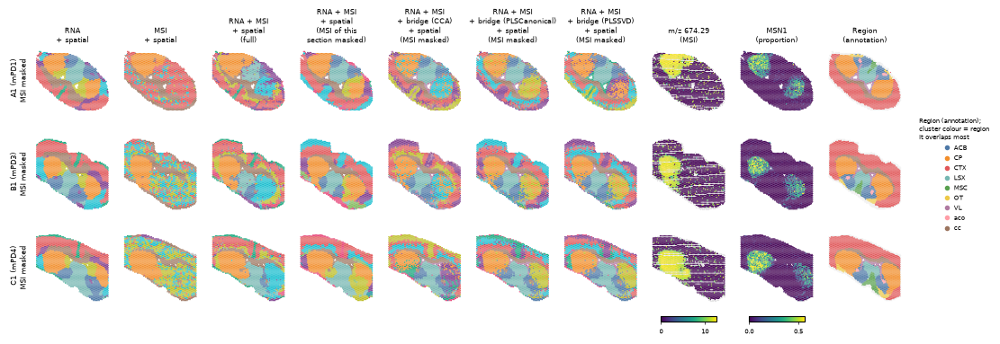

In [24]:
# Uses features / vmax / panel_mm / END_ANNOTATION / shown_regions from the feature figure and cluster_colors /
# region_color / shade / xy / FIG_WIDTH_MM / ROW_HEIGHT_MM / POINT_SIZE from the cluster figure above.
MASK_FIG_NAME = "masking_per_section_with_features"
# file name -> columns; one figure with the bridges on PCs, one with the bridges on genes x m/z
MASK_FIGS = {
    MASK_FIG_NAME: ["RNA only", "MSI only", "Full MSI", "Isolated", "Bridge: CCA", "Bridge: PLSCanonical", "Bridge: PLSSVD"],
    # e.g. ["RNA only", "Full MSI", "Isolated", "Bridge: ridge CCA", "Bridge: CCA"] for the ridge vs sklearn CCA comparison
    **({f"{MASK_FIG_NAME}_genes_mz": ["RNA only", "Full MSI", "Isolated", *[f"Bridge: {b}{FEATURE_SUFFIX}" for b in ["CCA", "PLSCanonical", "PLSSVD"]]]}
       if FEATURE_BRIDGES else {}),
}
MASK_TITLES = {"RNA only": "RNA\n+ spatial", "MSI only": "MSI\n+ spatial", "Full MSI": "RNA + MSI\n+ spatial\n(full)",
               "Isolated": "RNA + MSI\n+ spatial\n(MSI of this\nsection masked)",
               **{f"Bridge: {name}": "RNA + MSI\n+ bridge ({})\n+ spatial\n(MSI masked)".format(name.replace(FEATURE_SUFFIX, ",\ngenes × m/z")) for _, name, _ in BRIDGES.values()}}

# feature columns of this figure (keys of `features` from the feature figure): MSI peak(s) and cell-type proportions
MASK_FEATURES = [k for k in features if "(RNA)" not in k]  # e.g. list(features) to also show the genes
mask_features = {k: features[k] for k in MASK_FEATURES}

for fig_name, methods in MASK_FIGS.items():
    mask_colors = {key: cluster_colors(labels, sub_obs)[0] for key, labels in mask_labels.items()}

    mm = 1 / 25.4
    n_cluster_maps = len(methods)
    n_end = len(END_ANNOTATION)
    n_cols = n_cluster_maps + len(mask_features) + n_end + 1  # + legend
    width_ratios = [1] * n_cluster_maps + [1] * len(mask_features) + [1] * n_end + [0.75]
    fig, axes = plt.subplots(
        len(MASK_SECTIONS) + 1, n_cols,
        figsize=(panel_mm * sum(width_ratios) * mm, ROW_HEIGHT_MM * mm * len(MASK_SECTIONS) + 6 * mm),
        gridspec_kw={"width_ratios": width_ratios, "height_ratios": [1] * len(MASK_SECTIONS) + [0.06],
                     "wspace": 0.12, "hspace": 0.06}, squeeze=False,
    )
    for row, section_name in enumerate(MASK_SECTIONS):
        spots = sub_obs.index[sub_obs["section"] == section_name]
        obs = sub_obs.loc[spots]
        region_here = obs["RegionLoupe"].astype(str)
        lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
        # cluster maps
        for col, method in enumerate(methods):
            ax = axes[row, col]
            labels, colors = mask_labels[section_name, method], mask_colors[section_name, method]
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=[colors.get(c, "#bdbdbd") for c in labels[spots]],
                       linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(MASK_TITLES.get(method, method), pad=3, va="bottom", fontsize=5.5)
        # feature maps
        for j, (title, values) in enumerate(mask_features.items()):
            ax = axes[row, n_cluster_maps + j]
            vals = values.reindex(spots)
            shown = vals.dropna().index
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c="#e5e5e5", linewidth=0, rasterized=True)
            sc_ = ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=POINT_SIZE, c=vals[shown], cmap=FEATURE_CMAP,
                             vmin=0, vmax=vmax[title], linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
            if row == len(MASK_SECTIONS) - 1:  # colour bar below the last row
                cax = axes[-1, n_cluster_maps + j]
                pos = cax.get_position()
                cax.set_position([pos.x0 + pos.width * 0.15, pos.y0, pos.width * 0.7, pos.height])
                fig.colorbar(sc_, cax=cax, orientation="horizontal").ax.tick_params(labelsize=5, width=0.5, length=2)
        # annotation after the mask_features
        end_maps = {
            "region": ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
            "region x lesion": ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                                                   for r, l in zip(region_here, lesioned_here)]),
        }
        for j, key in enumerate(END_ANNOTATION):
            title, colors = end_maps[key]
            ax = axes[row, n_cluster_maps + len(mask_features) + j]
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=colors, linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
        for ax in axes[row, :-1]:
            ax.set_aspect(1)
            ax.invert_yaxis()
            ax.axis("off")
        slide_name, sec = section_name.split("_")
        row_label = f"{sec} ({obs['mouse'].iloc[0]})\nMSI masked" if len(slides) == 1 else f"{SLIDES[slide_name]['tissue'].replace('_', ' ')}\n{sec} ({obs['mouse'].iloc[0]}), MSI masked"
        axes[row, 0].text(-0.06, 0.5, row_label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
        axes[row, -1].axis("off")
    for ax in [*axes[-1, :n_cluster_maps], *axes[-1, n_cluster_maps + len(mask_features):]]:
        ax.axis("off")
    axes[-1, -1].axis("off")

    axes[len(MASK_SECTIONS) // 2, -1].legend(
        handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in shown_regions]
        + ([plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
            for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]]
           if "region x lesion" in END_ANNOTATION else []),
        loc="center left", frameon=False, handletextpad=0.1, title_fontsize=5,
        title="Region (annotation shaded:\nlight = intact, dark = lesioned)" if "region x lesion" in END_ANNOTATION
        else "Region (annotation);\ncluster colour = region\nit overlaps most",
    )
    fig.savefig(out_dir / f"{fig_name}.pdf", dpi=600, bbox_inches="tight")
    fig.savefig(out_dir / f"{fig_name}.png", dpi=300, bbox_inches="tight")
    plt.show()


## Masking: all sections of the same clusterings

One figure per masked section (`masking_A1_all_sections`, `…_B1_…`, `…_C1_…`). Rows: all MALDI sections; the masked section (red label) has no MSI of its own and is connected to the others only through RNA, spatial and the bridge layer, the other sections are clustered with their MSI. Every column is one clustering, coloured once over all sections, so a colour means the same cluster in every row of that column: the question is whether the intact and lesioned CP of the masked section fall into the same clusters as in the sections with MSI. The dopamine column of the masked section shows its real MSI only for comparison (it is not used). Colours are not comparable between columns.

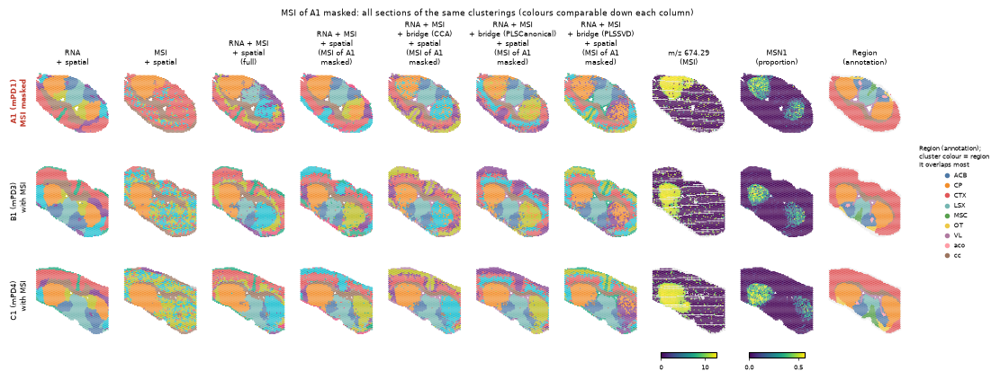

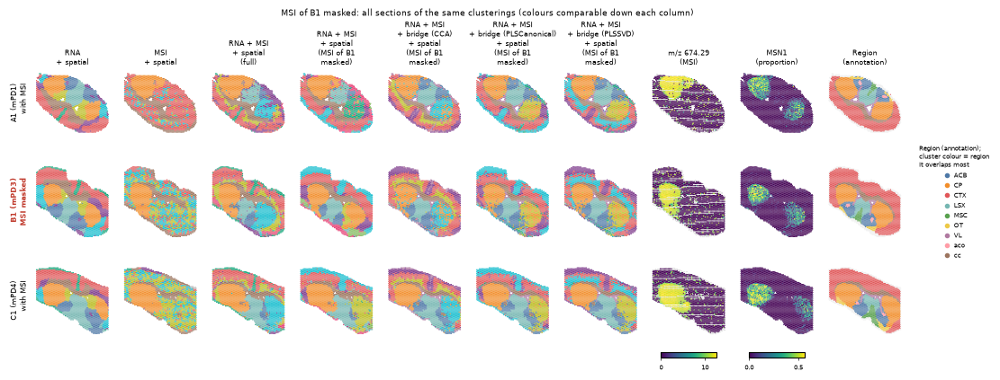

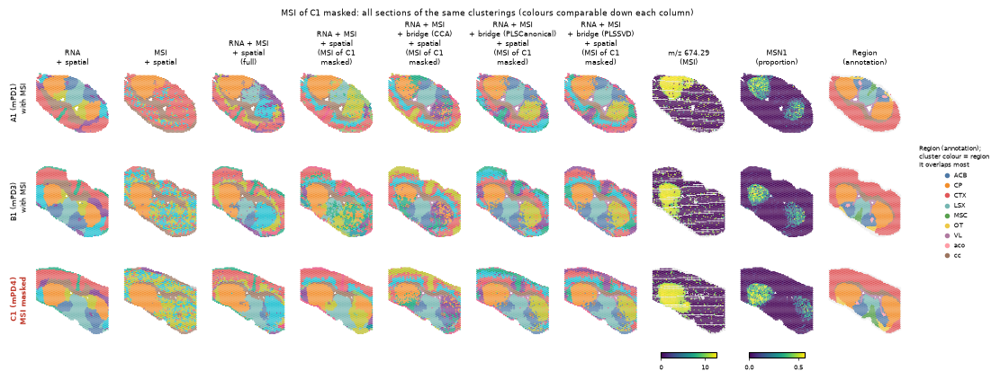

In [25]:
# One figure per masked section: all MALDI sections (rows) of the same clusterings, so the masked section (no own MSI,
# connected through the bridge) can be compared with the sections whose MSI was used. Every column is one clustering,
# coloured once over all sections, so the cluster colours are comparable down a column (not between columns).
# Uses MASK_FIGS / MASK_TITLES / mask_features / vmax / panel_mm / END_ANNOTATION / shown_regions from the cells above.
ALL_SECTIONS_FIG_NAME = "masking_{sec}_all_sections"
ALL_SECTIONS_METHODS = MASK_FIGS[MASK_FIG_NAME]  # columns, e.g. ["Full MSI", "Isolated", "Bridge: PLSCanonical"]
MASKED_LABEL_COLOR = "#C0392B"

mm = 1 / 25.4
for masked_section in MASK_SECTIONS:
    msec = masked_section.split("_")[1]
    methods = ALL_SECTIONS_METHODS
    colors_here = {m: cluster_colors(mask_labels[masked_section, m], sub_obs)[0] for m in methods}
    titles = {m: MASK_TITLES.get(m, m).replace("(MSI of this\nsection masked)", f"(MSI of {msec}\nmasked)")
                                      .replace("(MSI masked)", f"(MSI of {msec}\nmasked)") for m in methods}
    n_cluster_maps = len(methods)
    n_end = len(END_ANNOTATION)
    n_cols = n_cluster_maps + len(mask_features) + n_end + 1  # + legend
    width_ratios = [1] * n_cluster_maps + [1] * len(mask_features) + [1] * n_end + [0.75]
    fig, axes = plt.subplots(
        len(MASK_SECTIONS) + 1, n_cols,
        figsize=(panel_mm * sum(width_ratios) * mm, ROW_HEIGHT_MM * mm * len(MASK_SECTIONS) + 12 * mm),
        gridspec_kw={"width_ratios": width_ratios, "height_ratios": [1] * len(MASK_SECTIONS) + [0.06],
                     "wspace": 0.12, "hspace": 0.06}, squeeze=False,
    )
    fig.suptitle(f"MSI of {msec} masked: all sections of the same clusterings (colours comparable down each column)",
                 y=1.0, fontsize=6.5)
    for row, section_name in enumerate(MASK_SECTIONS):
        spots = sub_obs.index[sub_obs["section"] == section_name]
        obs = sub_obs.loc[spots]
        region_here = obs["RegionLoupe"].astype(str)
        lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
        # cluster maps: the same clustering (masked_section, method) in every row
        for col, method in enumerate(methods):
            ax = axes[row, col]
            labels, colors = mask_labels[masked_section, method], colors_here[method]
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=[colors.get(c, "#bdbdbd") for c in labels[spots]],
                       linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(titles[method], pad=3, va="bottom", fontsize=5.5)
        # feature maps (for the masked section: its real MSI, shown only for comparison)
        for j, (title, values) in enumerate(mask_features.items()):
            ax = axes[row, n_cluster_maps + j]
            vals = values.reindex(spots)
            shown = vals.dropna().index
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c="#e5e5e5", linewidth=0, rasterized=True)
            sc_ = ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=POINT_SIZE, c=vals[shown], cmap=FEATURE_CMAP,
                             vmin=0, vmax=vmax[title], linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
            if row == len(MASK_SECTIONS) - 1:  # colour bar below the last row
                cax = axes[-1, n_cluster_maps + j]
                pos = cax.get_position()
                cax.set_position([pos.x0 + pos.width * 0.15, pos.y0, pos.width * 0.7, pos.height])
                fig.colorbar(sc_, cax=cax, orientation="horizontal").ax.tick_params(labelsize=5, width=0.5, length=2)
        # annotation after the features
        end_maps = {
            "region": ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
            "region x lesion": ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                                                   for r, l in zip(region_here, lesioned_here)]),
        }
        for j, key in enumerate(END_ANNOTATION):
            title, colors = end_maps[key]
            ax = axes[row, n_cluster_maps + len(mask_features) + j]
            ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c=colors, linewidth=0, rasterized=True)
            if row == 0:
                ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
        for ax in axes[row, :-1]:
            ax.set_aspect(1)
            ax.invert_yaxis()
            ax.axis("off")
        slide_name, sec = section_name.split("_")
        is_masked = section_name == masked_section
        row_label = f"{sec} ({obs['mouse'].iloc[0]})" + ("\nMSI masked" if is_masked else "\nwith MSI")
        axes[row, 0].text(-0.06, 0.5, row_label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right",
                          color=MASKED_LABEL_COLOR if is_masked else "black", fontweight="bold" if is_masked else "normal")
        axes[row, -1].axis("off")
    for ax in [*axes[-1, :n_cluster_maps], *axes[-1, n_cluster_maps + len(mask_features):]]:
        ax.axis("off")
    axes[-1, -1].axis("off")
    axes[len(MASK_SECTIONS) // 2, -1].legend(
        handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in shown_regions]
        + ([plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
            for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]]
           if "region x lesion" in END_ANNOTATION else []),
        loc="center left", frameon=False, handletextpad=0.1, title_fontsize=5,
        title="Region (annotation shaded:\nlight = intact, dark = lesioned)" if "region x lesion" in END_ANNOTATION
        else "Region (annotation);\ncluster colour = region\nit overlaps most",
    )
    name = ALL_SECTIONS_FIG_NAME.format(sec=msec)
    fig.savefig(out_dir / f"{name}.pdf", dpi=600, bbox_inches="tight")
    fig.savefig(out_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


## RNA bridge: what the CCA learns

For every masked section (rows), the CCA of the RNA bridge is fitted on the other sections as in the masking experiment. **Left:** canonical correlation per component on the training sections (black) and on the masked section (red, held out; its real MSI is used only for this evaluation). Components with a high held-out correlation carry MSI-related signal into the masked section. **Scatter:** RNA score against MSI score of the masked section for the components in `SHOW_CC`, coloured by lesion region and side. **Maps:** RNA score (what the bridge layer is built from) next to the MSI score (real MSI, not used for clustering), z-scored within the section. One figure per CCA implementation: `rna_bridge_cca.pdf/.png` (ridge CCA) and `rna_bridge_cca_sklearn.pdf/.png` (sklearn CCA).

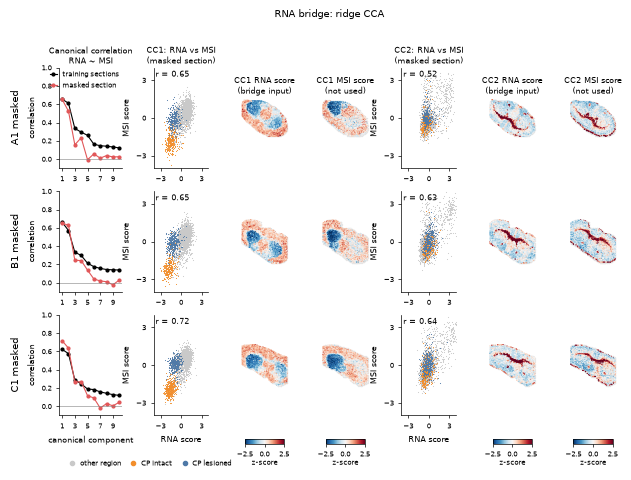

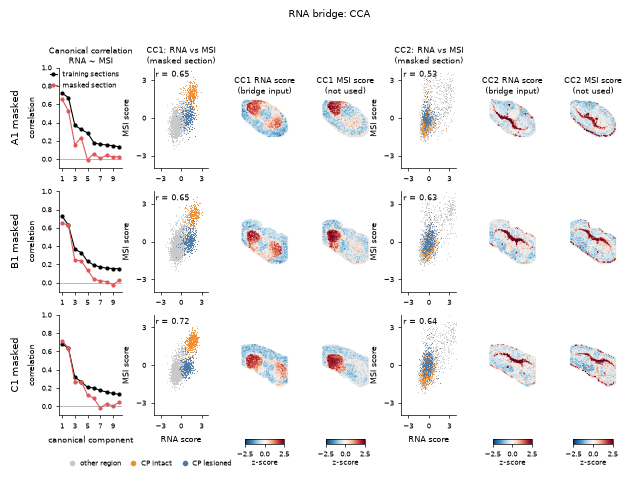

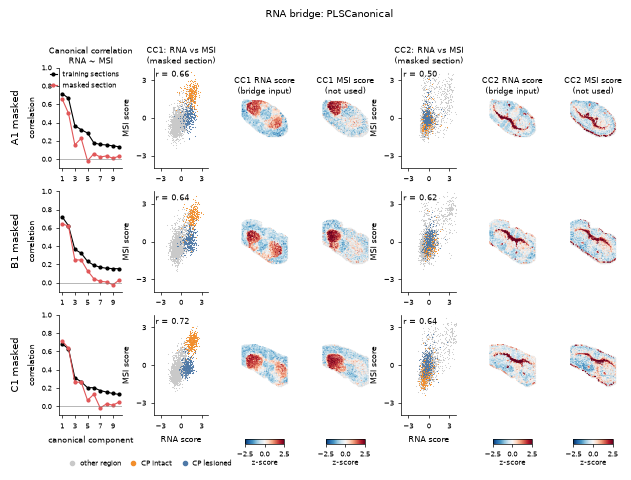

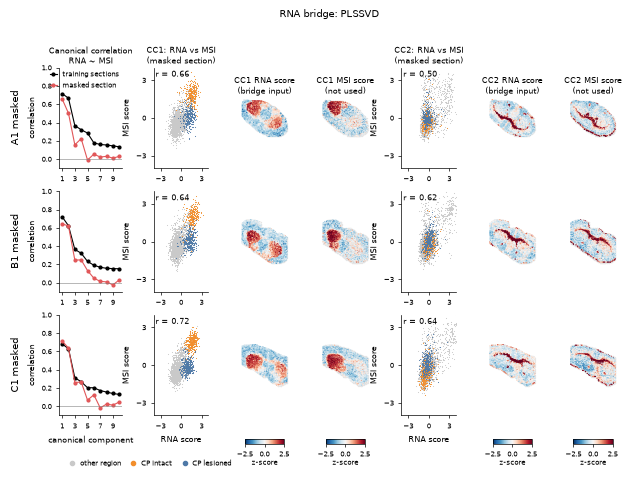

In [26]:
# CCA of the RNA bridge, for presentation: per masked section (rows) the canonical correlations, and for the
# components in SHOW_CC the RNA score (what the bridge uses) against the MSI score (real MSI of the masked section,
# only for evaluation) as scatter and as maps. One figure per CCA implementation (CCA_FITS from the masking cell). Uses fit_cca / msi_pca_without / bridge parameters from the masking cell.
BRIDGE_FIG_NAME = "rna_bridge_cca"
SHOW_CC = [0, 1]  # canonical components shown (0 = CC1)
GROUP_COLORS = {"other region": "#c9c9c9", f"{lesion_label} intact": "#F28E2B", f"{lesion_label} lesioned": "#4E79A7"}

CCA_SUFFIX = {layer: "" if layer == "rna_bridge" else "_" + layer.removeprefix("rna_bridge_") for layer in CCA_FITS}  # file name suffix
CCA_TITLES = {layer: f"RNA bridge: {name}" for layer, (_, name) in CCA_FITS.items()}

for layer, (fit, _) in CCA_FITS.items():
    rna_emb = pd.DataFrame(rna.obsm[rna_rep], index=rna.obs_names)
    bridge_cca, ref_weights = {}, None
    for masked_section in MASK_SECTIONS:
        m_rest = msi_pca_without(masked_section)
        cca = fit(rna_emb.loc[m_rest.obs_names].to_numpy(), m_rest.obsm["X_pca"], bridge_n_components, bridge_reg)
        # the sign of a canonical component is arbitrary: align it to the first masked section through the RNA weights
        # (all rows share the same RNA input space); RNA and MSI weights are flipped together, correlations are unchanged
        if ref_weights is None:
            ref_weights = cca["Wx"]
        flip = np.where(np.sum(cca["Wx"] * ref_weights, axis=0) < 0, -1.0, 1.0)
        cca["Wx"], cca["Wy"] = cca["Wx"] * flip, cca["Wy"] * flip
        spots = sub_obs.index[sub_obs["section"] == masked_section]
        held = msi.obs_names[(msi.obs["section"] == masked_section).to_numpy()]
        M = msi[held].X
        M = M.toarray() if sp.issparse(M) else np.asarray(M)
        Yh = (M - np.asarray(m_rest.X.mean(axis=0)).ravel()) @ m_rest.varm["PCs"]
        u = pd.DataFrame((rna_emb.loc[spots].to_numpy() - cca["mx"]) / cca["sx"] @ cca["Wx"], index=spots)  # RNA scores, all spots
        v = pd.DataFrame((Yh - cca["my"]) / cca["sy"] @ cca["Wy"], index=held)                             # MSI scores, spots with MSI
        held_corr = np.array([np.corrcoef(u.loc[held, i], v[i])[0, 1] for i in range(u.shape[1])])
        # z-score every component within the section, so RNA and MSI maps share one colour scale
        u, v = (u - u.loc[held].mean()) / u.loc[held].std(), (v - v.mean()) / v.std()
        in_region = sub_obs.loc[held, "in_lesion_region"].to_numpy()
        side = sub_obs.loc[held, "lesion"].astype(str).to_numpy()
        group = np.where(in_region & (side == "intact"), f"{lesion_label} intact",
                         np.where(in_region & (side == "lesioned"), f"{lesion_label} lesioned", "other region"))
        bridge_cca[masked_section] = {"train": cca["corr"], "held": held_corr, "u": u, "v": v, "held_spots": held,
                                      "group": pd.Series(group, index=held)}

    plt.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
        "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
        "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
        "ytick.major.size": 2, "pdf.fonttype": 42, "svg.fonttype": "none",
    })
    mm = 1 / 25.4
    n_rows = len(MASK_SECTIONS)
    col_kinds = ["corr"] + [k for _ in SHOW_CC for k in ("scatter", "rna map", "msi map")]
    width_ratios = [1.15] + [1.0, 0.9, 0.9] * len(SHOW_CC)
    fig, axes = plt.subplots(n_rows + 1, len(col_kinds), figsize=(183 * mm, 38 * mm * n_rows + 10 * mm),
                             gridspec_kw={"width_ratios": width_ratios, "height_ratios": [1] * n_rows + [0.05],
                                          "wspace": 0.6, "hspace": 0.3}, squeeze=False)
    vlim = 2.5  # colour scale of the maps in z-units (clipped)
    for row, masked_section in enumerate(MASK_SECTIONS):
        d = bridge_cca[masked_section]
        sec = masked_section.split("_")[1]
        spots = d["u"].index
        # canonical correlations: training sections vs masked section
        ax = axes[row, 0]
        k = np.arange(1, len(d["train"]) + 1)
        ax.plot(k, d["train"], "-o", ms=2, lw=0.8, color="#000000", label="training sections")
        ax.plot(k, d["held"], "-o", ms=2, lw=0.8, color="#E15759", label="masked section")
        ax.axhline(0, lw=0.4, color="#808080")
        ax.set(xticks=k[::2] if len(k) > 6 else k, ylim=(-0.1, 1), ylabel="correlation")
        if row == n_rows - 1:
            ax.set_xlabel("canonical component")
        ax.spines[["top", "right"]].set_visible(False)
        ax.text(-0.62, 0.5, f"{sec} masked", transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=7)
        if row == 0:
            ax.set_title("Canonical correlation\nRNA ~ MSI", pad=3)
            ax.legend(frameon=False, loc="upper right", handlelength=1.0, borderaxespad=0)
        for j, cc in enumerate(SHOW_CC):
            held = d["held_spots"]
            # scatter: RNA score vs MSI score on the masked section
            ax = axes[row, 1 + 3 * j]
            for g, col in GROUP_COLORS.items():
                sel = (d["group"] == g).to_numpy()
                ax.scatter(d["u"].loc[held, cc][sel], d["v"][cc][sel], s=0.6, c=col, linewidth=0, rasterized=True,
                           label=g, zorder=1 if g == "other region" else 2)
            ax.text(0.03, 0.97, f"r = {d['held'][cc]:.2f}", transform=ax.transAxes, va="top", fontsize=5.5)
            ax.set(ylabel="MSI score", xlim=(-4, 4), ylim=(-4, 4), xticks=[-3, 0, 3], yticks=[-3, 0, 3])
            if row == n_rows - 1:
                ax.set_xlabel("RNA score")
            ax.spines[["top", "right"]].set_visible(False)
            if row == 0:
                ax.set_title(f"CC{cc + 1}: RNA vs MSI\n(masked section)", pad=3)
            # maps: RNA score (all spots, used by the bridge) and MSI score (real MSI, evaluation only)
            for t, (kind, values, title) in enumerate([
                ("rna map", d["u"][cc], f"CC{cc + 1} RNA score\n(bridge input)"),
                ("msi map", d["v"][cc], f"CC{cc + 1} MSI score\n(not used)"),
            ]):
                ax = axes[row, 2 + 3 * j + t]
                ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=POINT_SIZE, c="#e5e5e5", linewidth=0, rasterized=True)
                shown = values.index
                im = ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=POINT_SIZE, c=values.clip(-vlim, vlim), cmap="RdBu_r",
                                vmin=-vlim, vmax=vlim, linewidth=0, rasterized=True)
                ax.set_aspect(1)
                ax.invert_yaxis()
                ax.axis("off")
                if row == 0:
                    ax.set_title(title, pad=3)
                if row == n_rows - 1:
                    cax = axes[-1, 2 + 3 * j + t]
                    pos = cax.get_position()
                    cax.set_position([pos.x0 + pos.width * 0.1, pos.y0, pos.width * 0.8, pos.height])
                    cb = fig.colorbar(im, cax=cax, orientation="horizontal")
                    cb.ax.tick_params(labelsize=5, width=0.5, length=2)
                    cb.set_label("z-score", fontsize=5, labelpad=1)
    for j, kind in enumerate(col_kinds):
        if kind not in ("rna map", "msi map"):
            axes[-1, j].axis("off")
    # legend of the scatter colours below the first two columns
    fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=col, label=g) for g, col in GROUP_COLORS.items()],
               loc="upper left", bbox_to_anchor=(axes[-1, 0].get_position().x0, axes[-1, 0].get_position().y0 - 0.02),
               ncol=len(GROUP_COLORS), frameon=False, handletextpad=0.1, columnspacing=0.8)
    fig.suptitle(CCA_TITLES[layer], y=1.0, fontsize=7)
    fig.savefig(out_dir / f"{BRIDGE_FIG_NAME}{CCA_SUFFIX[layer]}.pdf", dpi=600, bbox_inches="tight")
    fig.savefig(out_dir / f"{BRIDGE_FIG_NAME}{CCA_SUFFIX[layer]}.png", dpi=300, bbox_inches="tight")
    plt.show()


## RNA and MSI are complementary (one section)

For `SYNERGY_SECTION` (C1): **a**, UMAP of RNA and **b**, UMAP of MSI of this section, only the lesion-region spots coloured (orange intact, blue lesioned). **c**, RNA PC space (`rna_rep`, PC1 vs PC2). **d**, the RNA of this section projected onto the bridge axes (`SYNERGY_LAYER`, PLSCanonical on PC space) that were learned together with MSI on the **other** sections only, as for the bridge layer. **e**, the real MSI of this section projected onto the same fit (reference). **f**, separation of intact vs lesioned lesion-region spots as AUC (max(AUC, 1 − AUC), since the sign of a component is arbitrary): RNA PC1, the first projected RNA component (found without any labels, only guided by MSI of the other sections) and the first MSI component. RNA alone does not separate the lesion sides, but the MSI-guided projection of the same RNA does: the information is in the RNA, MSI shows where. No MSI values are predicted. Saved as `rna_msi_synergy_C1.pdf/.png`.

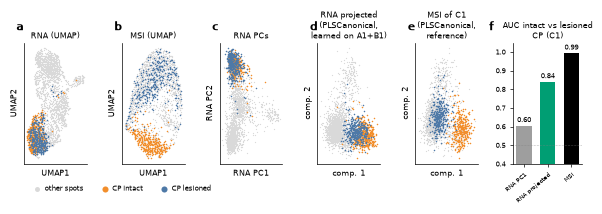

{'RNA PC1': 0.605, 'RNA projected': 0.84, 'MSI': 0.994}


In [27]:
# RNA and MSI are complementary: for one section, RNA alone does not separate intact from lesioned CP, MSI does, and
# RNA projected onto the axes learned together with MSI on the OTHER sections (held out, as for the bridge) does too.
# No MSI values are predicted; the projection only re-weights the RNA PCs. Only lesion-region spots are coloured.
SYNERGY_SECTION = [s for s in MASK_SECTIONS if s.endswith("_C1")][0]  # section shown
SYNERGY_LAYER = "rna_bridge_plscanonical"                               # key of CCA_FITS (PLSCanonical on PC space)
SYNERGY_FIG_NAME = "rna_msi_synergy_{sec}"
SYN_COLORS = {"other": "#d9d9d9", f"{lesion_label} intact": "#F28E2B", f"{lesion_label} lesioned": "#4E79A7"}

fit, method_name = CCA_FITS[SYNERGY_LAYER]
syn_sec = SYNERGY_SECTION.split("_")[1]
# fit on the paired spots of the other sections (MSI PCs fitted without SYNERGY_SECTION), as in rna_bridge_graph
m_rest = msi_pca_without(SYNERGY_SECTION)
rna_emb = pd.DataFrame(rna.obsm[rna_rep], index=rna.obs_names)
proj = fit(rna_emb.loc[m_rest.obs_names].to_numpy(), m_rest.obsm["X_pca"], bridge_n_components, bridge_reg)
# project the held-out section: RNA of all its spots, its real MSI (only for the MSI panels)
rna_spots = sub_obs.index[sub_obs["section"] == SYNERGY_SECTION]
msi_spots = msi.obs_names[(msi.obs["section"] == SYNERGY_SECTION).to_numpy()]
u = pd.DataFrame((rna_emb.loc[rna_spots].to_numpy() - proj["mx"]) / proj["sx"] @ proj["Wx"], index=rna_spots)
M = to_dense(msi[msi_spots].X).astype(float)
Yh = (M - np.asarray(m_rest.X.mean(axis=0)).ravel()) @ m_rest.varm["PCs"]
v = pd.DataFrame((Yh - proj["my"]) / proj["sy"] @ proj["Wy"], index=msi_spots)
u, v = (u - u.mean()) / u.std(), (v - v.mean()) / v.std()
pcs = pd.DataFrame(rna_emb.loc[rna_spots].to_numpy(), index=rna_spots)
pcs = (pcs - pcs.mean()) / pcs.std()


def cp_group(index):
    obs = sub_obs.loc[index]
    side = obs["lesion"].astype(str).to_numpy()
    in_region = obs["in_lesion_region"].to_numpy()
    return pd.Series(np.where(in_region & (side == "intact"), f"{lesion_label} intact",
                     np.where(in_region & (side == "lesioned"), f"{lesion_label} lesioned", "other")), index=index)


def umap_of(emb, index):
    a = ad.AnnData(obs=pd.DataFrame(index=index), obsm={"emb": np.asarray(emb)})
    sc.pp.neighbors(a, n_neighbors=n_neighbors, use_rep="emb", random_state=seed)
    sc.tl.umap(a, random_state=seed)
    return pd.DataFrame(a.obsm["X_umap"], index=index)


umap_rna = umap_of(rna_emb.loc[rna_spots].to_numpy(), rna_spots)
umap_msi = umap_of(msi[msi_spots].obsm["X_pca"], msi_spots)


def auc_sep(values, index):
    # separation of intact vs lesioned lesion-region spots; sign of a component is arbitrary -> max(AUC, 1 - AUC)
    g = cp_group(index)
    keep = (g != "other").to_numpy()
    auc = roc_auc_score((g[keep] == f"{lesion_label} intact").to_numpy(), np.asarray(values)[keep])
    return max(auc, 1 - auc)


train_secs = "+".join(s.split("_")[1] for s in MASK_SECTIONS if s != SYNERGY_SECTION)
aucs = {
    "RNA\nPC1": auc_sep(pcs[0], rna_spots),
    "RNA\nprojected": auc_sep(u[0], rna_spots),                   # first component, found without labels
    "MSI": auc_sep(v[0], msi_spots),
}

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
    "ytick.major.size": 2, "pdf.fonttype": 42, "svg.fonttype": "none",
})
mm = 1 / 25.4
fig, axes = plt.subplots(1, 6, figsize=(183 * mm, 40 * mm), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 1.1], "wspace": 0.55})
panels = [
    ("a", "RNA (UMAP)", umap_rna, rna_spots, ("UMAP1", "UMAP2")),
    ("b", "MSI (UMAP)", umap_msi, msi_spots, ("UMAP1", "UMAP2")),
    ("c", "RNA PCs", pcs[[0, 1]], rna_spots, ("RNA PC1", "RNA PC2")),
    ("d", f"RNA projected\n({method_name},\nlearned on {train_secs})", u[[0, 1]], rna_spots, ("comp. 1", "comp. 2")),
    ("e", f"MSI of {syn_sec}\n({method_name},\nreference)", v[[0, 1]], msi_spots, ("comp. 1", "comp. 2")),
]
for ax, (letter, title, coords, index, (xl, yl)) in zip(axes, panels):
    g = cp_group(index)
    coords = np.asarray(coords)
    for grp, col in SYN_COLORS.items():  # "other" first, underneath
        sel = (g == grp).to_numpy()
        ax.scatter(coords[sel, 0], coords[sel, 1], s=0.8 if grp == "other" else 1.2, c=col, linewidth=0, rasterized=True,
                   label=grp if grp != "other" else "other spots")
    ax.set(xlabel=xl, ylabel=yl, xticks=[], yticks=[])
    ax.set_title(title, pad=3, fontsize=5.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(-0.12, 1.08, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3, markerscale=4, handletextpad=0.1)
ax = axes[-1]
bar_colors = ["#9e9e9e", "#009E73", "#000000"]
ax.bar(range(len(aucs)), list(aucs.values()), color=bar_colors, width=0.65)
for i, val in enumerate(aucs.values()):
    ax.text(i, val + 0.01, f"{val:.2f}", ha="center", va="bottom", fontsize=5)
ax.axhline(0.5, lw=0.4, color="#808080", ls=":")
ax.set(ylim=(0.4, 1.05), xticks=range(len(aucs)))
ax.set_xticklabels([k.replace("\n", " ") for k in aucs], fontsize=4.5, rotation=40, ha="right", rotation_mode="anchor")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"AUC intact vs lesioned\n{lesion_label} ({syn_sec})", pad=3, fontsize=5.5)
ax.text(-0.35, 1.08, "f", transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
name = SYNERGY_FIG_NAME.format(sec=syn_sec)
fig.savefig(out_dir / f"{name}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / f"{name}.png", dpi=300, bbox_inches="tight")
plt.show()
print({k.replace("\n", " "): round(val, 3) for k, val in aucs.items()})


## Bridge methods: figure panels

Panels for the three established bridge methods (panel **a** is the masking figure `masking_per_section_with_features` above). Rows: masked section. **b**, correlation of the RNA and MSI component scores on the masked section (held out) per component. **c**, ARI lesion in the lesion region and **d**, ARI region of the masked section, for *RNA only*, *Full MSI*, *Isolated* and the three bridges on PCs (solid) and on genes × m/z (hatched / dashed); points are Leiden seeds (`MASK_SEEDS`), bars their mean. Saved as `rna_bridge_methods_panels.pdf/.png`.

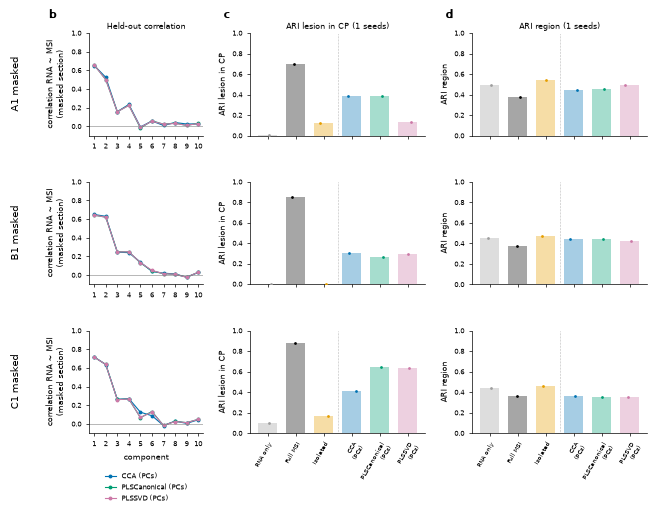

ARI lesion in CP     ARI region    
                                                mean std       mean std
masked section method                                                  
V11L12-109_A1  RNA only                        0.010 NaN      0.494 NaN
               Full MSI                        0.700 NaN      0.377 NaN
               Isolated                        0.123 NaN      0.546 NaN
               Bridge: CCA                     0.384 NaN      0.449 NaN
               Bridge: PLSCanonical            0.389 NaN      0.457 NaN
               Bridge: PLSSVD                  0.138 NaN      0.498 NaN
V11L12-109_B1  RNA only                       -0.003 NaN      0.452 NaN
               Full MSI                        0.855 NaN      0.377 NaN
               Isolated                       -0.004 NaN      0.470 NaN
               Bridge: CCA                     0.300 NaN      0.446 NaN
               Bridge: PLSCanonical            0.263 NaN      0.447 NaN
               Bridge: PLSSVD                  0.297 NaN      0.426 NaN
V11L12-109_C1  RNA only                        0.097 NaN      0.438 NaN
               Full MSI                        0.876 NaN      0.361 NaN
               Isolated                        0.163 NaN      0.462 NaN
               Bridge: CCA                     0.409 NaN      0.358 NaN
               Bridge: PLSCanonical            0.644 NaN      0.349 NaN
               Bridge: PLSSVD                  0.632 NaN      0.357 NaN

In [28]:
# Figure panels for the bridge methods (b-d; panel a is the masking figure above). Rows of each panel: masked sections.
# b: correlation of the RNA and MSI component scores on the masked section (held out) per component and method;
# c: ARI lesion in the lesion region, d: ARI region, every point one Leiden seed (MASK_SEEDS), bar = mean.
# Bridges on PCs: solid lines / filled bars; on genes x m/z: dashed lines / hatched bars.
PANEL_FIG_NAME = "rna_bridge_methods_panels"
PANEL_BRIDGES = ["CCA", "PLSCanonical", "PLSSVD"]  # methods shown, each on PCs and on genes x m/z; add "ridge CCA" (PCs only)
PANEL_INPUTS = ["", FEATURE_SUFFIX]               # "" = PCs, FEATURE_SUFFIX = genes x m/z
BASE_COLORS = {"RNA only": "#9e9e9e", "Full MSI": "#000000", "Isolated": "#E69F00", "ridge CCA": "#56B4E9",
               "CCA": "#0072B2", "PLSCanonical": "#009E73", "PLSSVD": "#CC79A7"}
bridge_names = [b + suffix for suffix in PANEL_INPUTS for b in PANEL_BRIDGES if b + suffix in [n for _, n, _ in BRIDGES.values()]]
PANEL_METHODS = ["RNA only", "Full MSI", "Isolated", *[f"Bridge: {b}" for b in bridge_names]]


def base_name(method):
    return method.replace("Bridge: ", "").replace(FEATURE_SUFFIX, "")


def label(method):
    name = method.replace("Bridge: ", "")
    return name.replace(FEATURE_SUFFIX, "\n(genes × m/z)") if FEATURE_SUFFIX in name else (name + "\n(PCs)" if method.startswith("Bridge") else name)


plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
    "ytick.major.size": 2, "pdf.fonttype": 42, "svg.fonttype": "none", "hatch.linewidth": 0.5,
})
mm = 1 / 25.4
metrics = [(f"ARI lesion in {lesion_label}", "c"), ("ARI region", "d")]
fig, axes = plt.subplots(len(MASK_SECTIONS), 3, figsize=(183 * mm, 44 * mm * len(MASK_SECTIONS)),
                         gridspec_kw={"width_ratios": [0.75, 1.15, 1.15], "wspace": 0.3, "hspace": 0.45}, squeeze=False)
rng = np.random.default_rng(0)
for row, masked_section in enumerate(MASK_SECTIONS):
    sec = masked_section.split("_")[1]
    last = row == len(MASK_SECTIONS) - 1
    # b: held-out correlation per component
    ax = axes[row, 0]
    for b in bridge_names:
        corr = bridge_info[masked_section, b]["held-out corr"]
        ax.plot(np.arange(1, len(corr) + 1), corr, "--" if FEATURE_SUFFIX in b else "-", marker="o", ms=1.8, lw=0.8,
                color=BASE_COLORS[base_name(b)], label=label("Bridge: " + b).replace("\n", " "))
    ax.axhline(0, lw=0.4, color="#808080")
    ax.set(ylim=(-0.1, 1), xticks=np.arange(1, bridge_n_components + 1), ylabel="correlation RNA ~ MSI\n(masked section)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(-0.6, 0.5, f"{sec} masked", transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=7)
    if last:
        ax.set_xlabel("component")
        ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), handlelength=1.6, ncol=1)
    if row == 0:
        ax.set_title("Held-out correlation", pad=3)
        ax.text(-0.35, 1.12, "b", transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
    # c, d: ARI per method, points = seeds
    df = mask_scores[mask_scores["masked section"] == masked_section]
    for j, (metric, letter) in enumerate(metrics, start=1):
        ax = axes[row, j]
        for i, method in enumerate(PANEL_METHODS):
            vals = df.loc[df["method"] == method, metric].to_numpy()
            col = BASE_COLORS[base_name(method)]
            feat = FEATURE_SUFFIX in method
            ax.bar(i, vals.mean(), width=0.7, facecolor="white" if feat else col, alpha=1 if feat else 0.35,
                   edgecolor=col, hatch="//////" if feat else None, linewidth=0.5 if feat else 0)
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(vals)), vals, s=4, color=col, linewidth=0, zorder=3)
        ax.set_xticks(range(len(PANEL_METHODS)))
        ax.set_xticklabels([label(m) for m in PANEL_METHODS] if last else [], rotation=60, ha="right", rotation_mode="anchor", fontsize=4.5)
        ax.set(ylim=(min(0, df[metric].min() * 1.1), 1), ylabel=metric)
        ax.axvline(2.5, lw=0.4, color="#808080", ls=":")  # references | bridges
        ax.spines[["top", "right"]].set_visible(False)
        if row == 0:
            ax.set_title(f"{metric} ({len(MASK_SEEDS)} seeds)", pad=3)
            ax.text(-0.15, 1.12, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
fig.savefig(out_dir / f"{PANEL_FIG_NAME}.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / f"{PANEL_FIG_NAME}.png", dpi=300, bbox_inches="tight")
plt.show()
display(mask_scores[mask_scores["method"].isin(PANEL_METHODS)]
        .groupby(["masked section", "method"], sort=False)[[f"ARI lesion in {lesion_label}", "ARI region"]]
        .agg(["mean", "std"]).round(3))
